# Talk vs. Walk: is greenwashing priced in stock returns?

**BMF5324 AI and Statistics for Financial Decision-Making · S03 Group 10**
Arya Garg, Peter Lesmana, Huiyi Zhang, Yannik Schiffner · October 2026

This notebook is the analysis behind our strategy memo *Talk vs. Walk: Greenwashing, ESG Ratings and Stock Returns*. It starts from the firm-year data we built, re-derives every number, table and figure in the memo, and checks at the end (section 11) that each one matches.

### The argument in four steps
1. **A measurable gap.** A firm can sound greener than it is. We measure the gap as the Greenwashing Index (GWI): how green the firm's 10-K sounds (*Talk*) minus how clean its emissions are (*Walk*), both ranked against sector peers in the same year.
2. **Two predictions.** If investors eventually see through the gap, firms with a high GWI should earn lower returns afterwards (H1), and more so after the 2015 Paris Agreement raised scrutiny of climate claims (H2).
3. **Neither holds reliably.** The top GWI fifth earns 0.9 percentage points (pp) a year less than the bottom fifth, but p = 0.35, and the gap shrinks after Paris rather than growing. The data still rule out a penalty larger than about 2.8 pp a year.
4. **The rating is the problem.** LSEG's Environmental Pillar score rewards disclosure and green talk, not lower emissions, so a screen built on it misses most of the firms our index flags. This is the memo's strongest result and the basis of its recommendation.

### How to run it
Open this notebook from the folder it came in (it needs `data/` and `requirements.txt` next to it) and run all cells: *Kernel → Restart & Run All* in Jupyter, or *Run All* in VS Code. No other input is needed. The first code cell checks the installed package versions against `requirements.txt` and installs the pinned versions if any differ. A full run takes about a minute. Figures 1-6 are written to `figures/`.

### Reproducibility
* **Packages:** Python 3.12 with the exact versions in `requirements.txt`, checked and if necessary installed in section 1.1.
* **Randomness:** the only random procedure is the permutation test in section 10. It uses seed 5324 (`SEED`), so every run gives the same p-values.
* **Data pulls:** the source, file and pull date of every dataset are listed in `data/PULL_DATES.csv` and shown in section 2.1, with a checksum of every data file.
* **Traceability:** every number in the memo is computed in a cell, and section 11 lists them all next to the memo's value. The run stops with an error if any of them differs.

### Contents and where each part of the memo comes from
| Notebook section | Memo |
|---|---|
| 1. Setup: pinned packages, imports, seed | |
| 2. Data: sources and pull dates, how the panel was built, the data audit | Part IV, 4.1 and 4.6 |
| 3. Sample | 4.1, Figure 2 |
| 4. Measuring Talk, Walk and the Greenwashing Index | 4.2-4.4, Figures 1 and 3 |
| 5. H1: do greenwashers earn lower returns? | 5.1, Table 1, Figure 4 |
| 6. H2: did the penalty grow after Paris? | 5.2, Table 2, Figure 5 |
| 7. Reaction to the 10-K filing | 5.3, Table 2 |
| 8. Robustness | 5.4, Table 3 |
| 9. What the ESG rating rewards | 5.5, Table 4 |
| 10. Sectors (exploratory) | 5.6, Figure 6 |
| 11. Every number in the memo, traced | all parts |
| 12. Session information | |

## 1. Setup

### 1.1 Pinned package versions
Regression output can shift slightly between package versions, for example through changes in quantile interpolation or in the small-sample correction of clustered standard errors. We therefore pin the exact versions we ran. This cell reads `requirements.txt`, compares it with what is installed (without importing anything yet) and installs the pinned versions if any differ.

In [1]:
import sys, subprocess, importlib.metadata as metadata

assert sys.version_info >= (3, 11), f'Python 3.11 or newer is needed (we used 3.12); this is {sys.version.split()[0]}'
PINNED = {}
for line in open('requirements.txt'):
    line = line.split('#')[0].strip()
    if '==' in line:
        name, version = (s.strip() for s in line.split('=='))
        PINNED[name] = version


def installed(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None


wrong = {n: v for n, v in PINNED.items() if installed(n) != v}
if wrong:
    print('Installing the pinned versions:', ', '.join(f'{n}=={v}' for n, v in wrong.items()))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet'] + [f'{n}=={v}' for n, v in wrong.items()])
    loaded = [n for n in wrong if n in sys.modules]
    if loaded:   # only happens if a package was imported before this cell, e.g. in a reused kernel
        raise SystemExit('Restart the kernel and run all cells again; already imported: ' + ', '.join(loaded))
print('Python', sys.version.split()[0], '| packages as pinned:', ', '.join(f'{n} {installed(n)}' for n in PINNED))

Installing the pinned versions: numpy==2.4.1, pandas==2.3.3, scipy==1.17.0, statsmodels==0.14.6, patsy==1.0.2, matplotlib==3.10.8


Python 3.12.10 | packages as pinned: numpy 2.4.1, pandas 2.3.3, scipy 1.17.0, statsmodels 0.14.6, patsy 1.0.2, matplotlib 3.10.8


### 1.2 Imports, seed, folders and plot style

In [2]:
import os, glob, hashlib, time, warnings, zipfile
import numpy as np
import pandas as pd
import scipy
from scipy import stats, sparse
import statsmodels
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
try:
    from IPython.display import display, Markdown
except ImportError:                                    # running outside Jupyter
    display = print
    Markdown = str

T0 = time.time()
SEED = 5324                     # used by the permutation test (section 10); fixed so every run gives the same p-values
np.random.seed(SEED)
N_SHUFFLE = 1000                # permutations in the sector test
warnings.simplefilter('ignore', FutureWarning)
# statsmodels warns about negative variances of some fixed-effect dummies under clustering; we never use those terms
warnings.filterwarnings('ignore', message='invalid value encountered in sqrt')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 90)

ROOT = os.path.abspath('.')
DATA = os.path.join(ROOT, 'data')
FIGS = os.path.join(ROOT, 'figures')
if not os.path.exists(os.path.join(DATA, 'panel.csv')) and os.path.exists('talk_vs_walk_final_data.zip'):
    zipfile.ZipFile('talk_vs_walk_final_data.zip').extractall(ROOT)     # the data folder also ships as a zip
assert os.path.exists(os.path.join(DATA, 'panel.csv')), 'data/panel.csv not found: run the notebook from its own folder'
os.makedirs(FIGS, exist_ok=True)

# figure style of the memo (NUS blue and orange); the memo's font is used if the fonts folder is present
BLUE, ORANGE = '#1F5FAA', '#D86B00'
INK, INK2, MUTED = '#172030', '#3E4A5C', '#566174'
GRID, AXIS, CONTEXT = '#E3E7ED', '#B9C2CF', '#C3C9D2'
for f in glob.glob(os.path.join(ROOT, 'fonts', '*.ttf')):
    font_manager.fontManager.addfont(f)
FAMILY = 'Barlow Semi Condensed' if any('Barlow' in f.name for f in font_manager.fontManager.ttflist) else 'DejaVu Sans'
plt.rcParams.update({
    'font.family': FAMILY, 'font.size': 10, 'axes.titlesize': 10.5, 'axes.labelcolor': INK2, 'axes.labelsize': 10,
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'xtick.color': AXIS,
    'ytick.color': AXIS, 'xtick.labelcolor': MUTED, 'ytick.labelcolor': MUTED, 'xtick.labelsize': 9,
    'ytick.labelsize': 9, 'legend.frameon': False, 'legend.fontsize': 9, 'lines.linewidth': 1.6,
    'figure.facecolor': 'white', 'savefig.facecolor': 'white', 'mathtext.fontset': 'dejavusans', 'figure.dpi': 100})
RING = dict(edgecolor='white', linewidth=1.1)
fmt = lambda v, d=2: f'{v:+.{d}f}'.replace('-', '−')          # signed number with a real minus sign


def save_figure(fig, name):
    """Lay out the figure as in the memo, save it at 300 dpi and show it."""
    fig.tight_layout(pad=0.7)
    if getattr(fig, '_fit_right', False):            # forest plots: let the number columns end at the right margin
        for _ in range(3):
            bb = fig.get_tightbbox(fig.canvas.get_renderer())
            w = fig.get_size_inches()[0]
            fig.subplots_adjust(right=min(0.995, fig.subplotpars.right + ((w - 0.1) - bb.x1) / w))
    fig.savefig(os.path.join(FIGS, name), dpi=300)
    plt.show()


print(f'Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | '
      f'statsmodels {statsmodels.__version__} | matplotlib {matplotlib.__version__} | seed {SEED} | font {FAMILY}')

Python 3.12.10 | numpy 2.4.1 | pandas 2.3.3 | scipy 1.17.0 | statsmodels 0.14.6 | matplotlib 3.10.8 | seed 5324 | font Barlow Semi Condensed


## 2. Data

### 2.1 Where the data come from, and when they were pulled
The analysis combines four providers: SEC EDGAR for the 10-K text and the financial statements, LSEG (Refinitiv) for emissions, revenue, the ESG rating, sectors and returns, Yahoo Finance as a cross-check for returns, and a public history of the S&P 500. The LSEG pulls need a licence (ours is the NUS course licence) and the Talk scores needed a GPU, so neither is repeated here. Instead we ship exactly what we pulled, record when we pulled it, and print a checksum of every file so a reader can confirm they are running on the same data.

In [3]:
pulls = pd.read_csv(os.path.join(DATA, 'PULL_DATES.csv'))
for _, r in pulls.iterrows():
    print(f"{r['source']}: pulled {r['pulled']}\n  provider and fields: {r['provider and fields']}\n"
          f"  what we took: {r['what we took']}\n  used for: {r['used for']}\n  file: {r['file in this package']}\n")


def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1 << 20), b''):
            h.update(block)
    return h.hexdigest()[:16]


files = sorted(glob.glob(os.path.join(DATA, '**', '*.*'), recursive=True))
checksums = pd.DataFrame({'file': [os.path.relpath(f, ROOT).replace(os.sep, '/') for f in files],
                          'size (kB)': [round(os.path.getsize(f) / 1e3) for f in files],
                          'sha256 (first 16 hex)': [sha256(f) for f in files]})
display(checksums)

S&P 500 membership: pulled September 2026
  provider and fields: GitHub fja05680/sp500 (index history) and Wikipedia "List of S&P 500 companies" (live page; index changes from the web.archive.org copy of June 2026)
  what we took: S&P 500 members on 31 December 2010-2024, names, SEC CIKs
  used for: sample (memo 4.1)
  file: raw/talk_scores.csv

SEC EDGAR 10-K text: pulled September 2026 (Talk run completed 29 September 2026)
  provider and fields: SEC EDGAR filings (Items 1, 1A and 7; Exhibit 13 where Item 7 is incorporated by reference)
  what we took: environmental sentences scored with FinBERT-ESG, FinBERT-tone and the Loughran-McDonald lists
  used for: Talk (memo 4.2)
  file: raw/talk_panel.csv

LSEG ESG and fundamentals: pulled final version 5 October 2026
  provider and fields: LSEG Workspace / Codebook: TR.CO2EmissionTotal, TR.AnalyticEstimatedCO2Total, TR.CO2EstimationMethod, TR.EnvironmentPillarScore, TR.F.TotRevenue, TR.Revenue, TR.F.PeriodEndDate, TRBC codes
  what we took

,file,size (kB),sha256 (first 16 hex)
0,data/PULL_DATES.csv,2,1db18578aa6d2681
1,data/data_dictionary.csv,7,5b075b23fd51677d
2,data/panel.csv,5116,4061ad582c60e578
3,data/raw/README.txt,3,dfee3adeb0669e1f
4,data/raw/audit_emissions_flags.csv,309,cbb675614714ae16
5,data/raw/audit_identity_remap.csv,6,d25e63c3fba60a41
6,data/raw/event_window_returns.csv,437,e198309bfcad6989
7,data/raw/lseg_emissions_revenue_esg.csv,1127,f815674039336901
8,data/raw/lseg_emissions_revenue_esg_replacement_rics.csv,17,2a78f65fd4d475f1
9,data/raw/lseg_firm_map.csv,94,103a966d343b1154


### 2.2 How the firm-year panel was built
The notebook starts from `data/panel.csv`, one row per S&P 500 firm and fiscal year. This is how its columns were made (memo Part IV).

**Sample.** Every firm in the S&P 500 on 31 December of a year from 2010 to 2024, including firms that later left the index through a takeover, delisting or bankruptcy, which avoids survivorship bias. *Year t* is the calendar year in which the fiscal year ends; fiscal years ending in January or in the first week of February count as the previous year. Talk, Walk and the controls are measured in year t, the return in year t+1.

**Talk: how green the 10-K sounds.** Items 1 (Business), 1A (Risk Factors) and 7 (MD&A) of each 10-K are split into sentences. Sentences with a word from an environmental keyword list are scored two ways. The *FinBERT measure* (`fb_talk_raw`) counts those that FinBERT-ESG (Huang, Wang and Yang, 2023) labels environmental and FinBERT-tone labels positive. The *Loughran-McDonald measure* (`lm_talk_raw`) counts those with more positive than negative words from the Loughran and McDonald (2011) lists, ignoring positive words within three words after a negation such as "not". Both are divided by all sentences of the three items. We use two measures because dictionaries are transparent but miss context, while FinBERT reads context but is a black box; averaging their ranks protects against the weaknesses of either. This step ran in a separate GPU notebook; its output is `data/raw/talk_panel.csv`.

**Walk: how clean the firm is.** Carbon intensity is reported Scope 1 plus Scope 2 emissions (LSEG `TR.CO2EmissionTotal`, tonnes CO2e) divided by revenue (USD m). Each 10-K is matched to the LSEG record of the same fiscal year: the LSEG period end must lie within 10 days of the 10-K's fiscal year end. We use reported emissions, not the ESG rating, because the literature (and section 9) shows that the rating partly rewards disclosure itself. Scope 3 is left out because it is mostly estimated.

**Ranking within sector and year.** Talk and Walk are percentiles within TRBC economic sector and year, computed on the firm-years that have both, in sector-years with at least five such firms. Ranking within peers matters because carbon intensity differs a hundredfold across sectors and green talk rose sharply over time; without it, Walk would measure the industry a firm is in and Talk the year it filed. Percentile = (rank − 1)/(n − 1) × 100, with tied firms sharing their average rank. Walk = 100 − the carbon-intensity percentile, so 100 is the cleanest firm in its sector-year.

**Greenwashing Index.** GWI = Talk − Walk, standardised to mean 0 and standard deviation 1. A firm with a high GWI sounds greener than its peers but emits more than them.

**Returns and controls.** The dependent variable is the total return including dividends over calendar year t+1 (LSEG `TR.TotalReturn`; Yahoo Finance as a cross-check and fallback), winsorised at 1% / 99% so a few extreme returns cannot drive a regression with 5,600 observations. Controls are size (log market value at the end of year t), ROA (net income ÷ total assets) and leverage (total liabilities ÷ total assets) from the XBRL statements of the same 10-K, also winsorised. The filing-day test uses the stock's daily total return minus the S&P 500 total return, summed over the filing day and the next two trading days.

### 2.3 Load the panel

In [ ]:
panel = pd.read_csv(os.path.join(DATA, 'panel.csv'), parse_dates=['filing_date'], dtype={'trbc': str})
dictionary = pd.read_csv(os.path.join(DATA, 'data_dictionary.csv'))
assert list(dictionary.column) == list(panel.columns)
print(f'{len(panel):,} firm-years, {panel.firm_id.nunique()} firms, {panel.shape[1]} columns '
      f'(meaning, unit and source of each column in data/data_dictionary.csv)')
with pd.option_context('display.max_colwidth', 120, 'display.max_rows', 100):
    display(dictionary.fillna(''))

### 2.4 The data audit (memo 4.1)
Before running any regression we checked the data firm by firm, because errors in identity, revenue or returns can manufacture or hide a result. The audit counts quoted in the memo come from flags in the panel and from the log of the panel build (`data/raw/panel_build_log.txt`).

In [5]:
build_log = open(os.path.join(DATA, 'raw', 'panel_build_log.txt'), encoding='utf-8').read()
log_count = lambda label: int(next(l for l in build_log.splitlines() if l.startswith(label)).split(':')[1].split()[0])
agilent = panel.loc[(panel.firm_id == 'A') & (panel.year == 2013)].iloc[0]
audit = pd.DataFrame([
    ('Firm-years re-linked to the right LSEG record (CIK of a subsidiary or old entity)', int(panel.remapped.sum()),
     'panel column remapped'),
    ('Firm-years where LSEG revenue was restated after a later divestiture: as-filed 10-K revenue used',
     int(panel.notes.fillna('').str.contains('revenue_asfiled_10K').sum()), 'panel column notes'),
    ('Agilent fiscal 2013 revenue, LSEG as delivered (US$ bn)', round(agilent.rev_lseg / 1e3, 1), 'panel rev_lseg'),
    ('Agilent fiscal 2013 revenue, 10-K as filed (US$ bn)', round(agilent.rev_final / 1e3, 1), 'panel rev_final'),
    ('Raw LSEG emission values confirmed as data errors and set to missing',
     log_count('Emission values blanked as data errors'), 'panel_build_log.txt'),
    ('Firm-years where LSEG reported a price-only return although dividends were paid (Yahoo total return used)',
     int((panel.ret_source == 'yahoo_divfix').sum()), 'panel column ret_source'),
], columns=['audit step', 'count', 'source'])
display(audit)

,audit step,count,source
0,Firm-years re-linked to the right LSEG record (CIK of a subsidiary or old entity),171.0,panel column remapped
1,Firm-years where LSEG revenue was restated after a later divestiture: as-filed 10-K re...,181.0,panel column notes
2,"Agilent fiscal 2013 revenue, LSEG as delivered (US$ bn)",3.9,panel rev_lseg
3,"Agilent fiscal 2013 revenue, 10-K as filed (US$ bn)",6.8,panel rev_final
4,Raw LSEG emission values confirmed as data errors and set to missing,47.0,panel_build_log.txt
5,Firm-years where LSEG reported a price-only return although dividends were paid (Yahoo...,59.0,panel column ret_source


## 3. Sample (memo 4.1, Figure 2)
We remove duplicate listings and 10-Ks matched to the wrong company, winsorise returns and controls over the 7,476 firm-years that remain, and define the regression sample: every firm-year with a GWI, a next-year return and all three controls. Standard errors are clustered by company (`entity`), because one company's results in different years are not independent; the entity joins share classes and a company's old and new SEC identifiers.

In [ ]:
P = panel[~panel.excluded].copy()                         # 7,476 firm-years after the identity corrections
for c in ['ret_cy', 'ret_aprmar', 'size_mv', 'size_assets', 'roa', 'lev', 'bm', 'mom']:
    lo_, hi_ = P[c].quantile([0.01, 0.99])
    P[c + '_w'] = P[c].clip(lo_, hi_)                     # _w = winsorised at 1% / 99%
P['ret'] = P['ret_cy_w'] * 100                            # next-year return, %
P['ret_am'] = P['ret_aprmar_w'] * 100                     # April-March return, %
r2 = (1 + P['ret_cy']) * (1 + P['ret_t2_lseg']) - 1      # two-year return t+1..t+2 (exploratory, section 5)
P['ret2y'] = r2.clip(*r2.quantile([0.01, 0.99])) * 100
P['entity_code'] = P['entity'].astype('category').cat.codes
P['sector_year'] = P['trbc'] + '_' + P['year'].astype(str)
CTRL = ['size_mv_w', 'roa_w', 'lev_w']
FE = 'C(trbc) + C(year)'                                  # sector and year fixed effects
base = P.dropna(subset=['gwi', 'ret'] + CTRL).copy().reset_index(drop=True)   # the regression sample

excl = panel.loc[panel.excluded, 'excluded_reason'].value_counts()
talk_ok = P.fb_talk_raw.notna() & P.lm_talk_raw.notna()
drop = {'no usable emissions data': int((talk_ok & P.ci.isna()).sum()), 'no Talk score': int((~talk_ok).sum()),
        'fewer than 5 sector peers': int((talk_ok & P.ci.notna() & P.gwi.isna()).sum())}
reporting = P.groupby('year')['ci'].apply(lambda s: s.notna().mean())   # share of firm-years with reported Scope 1+2
mv_no, mv_yes = P.loc[P.ci.isna(), 'mv'].median() / 1e3, P.loc[P.ci.notna(), 'mv'].median() / 1e3
src = base.ret_source.value_counts()
flow = pd.DataFrame([
    ('S&P 500 firm-years, 2010-2024', len(panel)),
    (f'removed: duplicate listings ({excl["duplicate listing"]}) and wrong-company 10-Ks ({excl["wrong-company 10-K"]})',
     -int(panel.excluded.sum())),
    ('after the identity corrections', len(P)),
    ('with Talk and reported emissions: GWI sample', int(P.gwi.notna().sum())),
    ('with a next-year return and all controls: regression sample', len(base)),
], columns=['step', 'firm-years'])
display(flow)
print('Dropped before the GWI sample:', ', '.join(f'{k} {v:,}' for k, v in drop.items()))
print(f'Regression sample: {base.firm_id.nunique()} firms = {base.entity.nunique()} companies (clusters)')
print(f'Firm-years with reported Scope 1+2 emissions: {reporting.loc[2010]:.0%} in 2010, {reporting.loc[2024]:.0%} in 2024')
print(f'Median market value: US$ {mv_no:.1f} bn without usable emissions data vs US$ {mv_yes:.1f} bn with')
print(f'Returns from Yahoo Finance in the regression sample: {src.get("yahoo", 0) + src.get("yahoo_divfix", 0)} of '
      f'{len(base):,} ({src.get("yahoo", 0)} with no LSEG return, {src.get("yahoo_divfix", 0)} where LSEG had only the '
      'price return)')

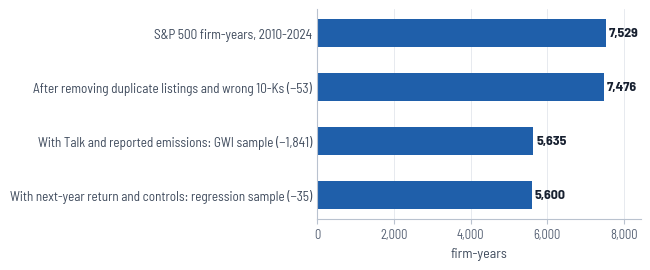

In [7]:
# Figure 2 of the memo
stages = [('S&P 500 firm-years, 2010-2024', len(panel)),
          (f'After removing duplicate listings and wrong 10-Ks ({len(P) - len(panel):,})', len(P)),
          (f'With Talk and reported emissions: GWI sample ({P.gwi.notna().sum() - len(P):,})', int(P.gwi.notna().sum())),
          (f'With next-year return and controls: regression sample ({len(base) - P.gwi.notna().sum():,})', len(base))]
fig, ax = plt.subplots(figsize=(6.5, 2.7))
y = np.arange(len(stages))[::-1]
ax.barh(y, [s[1] for s in stages], height=0.52, color=BLUE)
for yi, (_, v) in zip(y, stages):
    ax.text(v + 80, yi, f'{v:,}', va='center', fontsize=10, color=INK, fontweight=600)
ax.set_yticks(y, [s[0].replace('(-', '(−') for s in stages])
ax.tick_params(axis='y', length=0, labelcolor=INK2, labelsize=9.5)
ax.grid(axis='y', visible=False)
ax.set_xlim(0, len(panel) * 1.12)
ax.xaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
ax.set_xlabel('firm-years')
save_figure(fig, 'figure2_sample_flow.png')

**What we find.** Of 7,529 S&P 500 firm-years, 7,476 survive the identity corrections, 5,635 have both a Talk score and reported emissions, and 5,600 enter the regressions (673 firms, 651 companies). Almost all of the loss is missing emissions data, and that loss is not random: reporting rises from 60% of firm-years in 2010 to 94% in 2024, and firms without emissions data are about half the size of reporters (median market value USD 12.9 billion against USD 24.6 billion). Our results therefore describe large firms that disclose, which is the first limitation in the memo (6.2).

## 4. Measuring Talk, Walk and the Greenwashing Index (memo 4.2-4.4, Figures 1 and 3)
The panel already contains Talk, Walk and GWI. We rebuild them from their raw inputs to show that the formula in section 2.2 is exactly what produced them, and we check how well the two Talk measures agree.

In [8]:
def pct(s, groups):
    """(rank - 1) / (n - 1) x 100 within groups; tied firms share the average rank."""
    g = s.groupby(groups)
    return (g.rank(method='average') - 1) / (g.transform('count') - 1) * 100


s = P.dropna(subset=['fb_talk_raw', 'lm_talk_raw', 'ci', 'trbc']).copy()
s = s[s.groupby(['trbc', 'year'])['firm_id'].transform('size') >= 5]            # sector-years with at least 5 firms
grp = [s['trbc'], s['year']]
s['talk_check'] = pct((pct(s.fb_talk_raw, grp) + pct(s.lm_talk_raw, grp)) / 2, grp)
s['walk_check'] = 100 - pct(s.ci, grp)
raw_gap = s.talk_check - s.walk_check
s['gwi_check'] = (raw_gap - raw_gap.mean()) / raw_gap.std()
for a, b in [('talk_check', 'talk'), ('walk_check', 'walk'), ('gwi_check', 'gwi')]:
    print(f'{b:5s}: rebuilt for {len(s):,} firm-years, largest difference from the panel = {(s[a] - s[b]).abs().max():.1e}')
GWI_UNIT = raw_gap.std()
print(f'One GWI unit = {GWI_UNIT:.1f} rank points of Talk minus Walk')

gs = P.dropna(subset=['gwi']).copy()                      # the 5,635 GWI firm-years
g2 = [gs.trbc, gs.year]
r_talk_raw = gs[['fb_talk_raw', 'lm_talk_raw']].corr().iloc[0, 1]
r_talk_rank = np.corrcoef(pct(gs.fb_talk_raw, g2), pct(gs.lm_talk_raw, g2))[0, 1]
print(f'FinBERT vs Loughran-McDonald Talk, Pearson correlation: {r_talk_raw:.2f} for the raw shares, '
      f'{r_talk_rank:.2f} after ranking within sector-year')
top, bot = gs.gwi >= gs.gwi.quantile(.8), gs.gwi <= gs.gwi.quantile(.2)
print(f'GWI fifths: the top fifth averages {fmt(gs.gwi[top].mean())} units, the bottom fifth {fmt(gs.gwi[bot].mean())}')
rho_tw = gs[['talk', 'walk']].corr('spearman').iloc[0, 1]
print(f'Spearman correlation of Talk and Walk: {rho_tw:.2f}')
desc_cols = {'ret': 'Next-year return (%)', 'gwi': 'GWI (units)', 'talk': 'Talk (0-100)', 'walk': 'Walk (0-100)',
             'ci': 'Carbon intensity (t CO2e per US$ m revenue)', 'mv_bn': 'Market value (US$ bn)',
             'roa_pct': 'ROA (%)', 'lev_pct': 'Leverage (%)'}
desc = (base.assign(mv_bn=base.mv / 1000, roa_pct=base.roa_w * 100, lev_pct=base.lev_w * 100)[list(desc_cols)]
        .describe().T.rename(index=desc_cols))
print(f'\nDescriptive statistics of the regression sample (N = {len(base):,}); returns and controls winsorised')
display(desc[['mean', 'std', '25%', '50%', '75%']].round(2))

talk : rebuilt for 5,635 firm-years, largest difference from the panel = 1.4e-14
walk : rebuilt for 5,635 firm-years, largest difference from the panel = 1.4e-14
gwi  : rebuilt for 5,635 firm-years, largest difference from the panel = 8.9e-16
One GWI unit = 45.2 rank points of Talk minus Walk
FinBERT vs Loughran-McDonald Talk, Pearson correlation: 0.87 for the raw shares, 0.69 after ranking within sector-year
GWI fifths: the top fifth averages +1.40 units, the bottom fifth −1.42
Spearman correlation of Talk and Walk: -0.17

Descriptive statistics of the regression sample (N = 5,600); returns and controls winsorised


,mean,std,25%,50%,75%
Next-year return (%),12.38,28.60,-5.71,11.54,28.93
GWI (units),-0.00,1.00,-0.75,0.00,0.76
Talk (0-100),49.94,29.39,22.84,50.00,75.76
Walk (0-100),49.97,29.68,24.18,50.00,75.76
Carbon intensity (t CO2e per US$ m revenue),331.71,944.36,10.11,31.11,138.88
Market value (US$ bn),62.60,165.81,13.31,24.86,55.63
ROA (%),6.49,6.50,2.53,5.56,9.70
Leverage (%),64.83,20.26,50.72,64.40,78.39


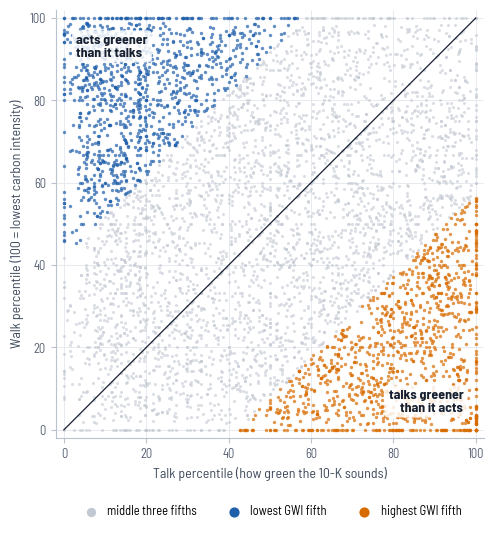

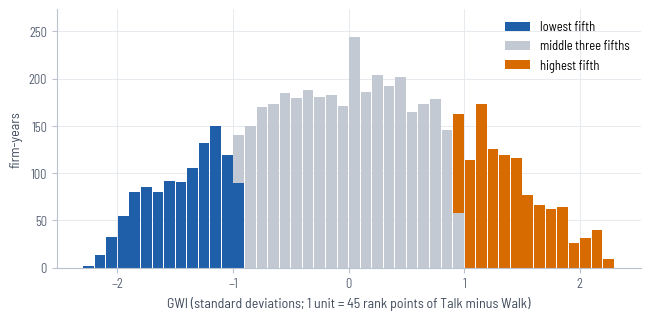

In [9]:
# Figure 1 of the memo: Talk against Walk
mid = ~top & ~bot
fig, ax = plt.subplots(figsize=(6.0, 5.3))
ax.scatter(gs.talk[mid], gs.walk[mid], s=5, color=CONTEXT, alpha=.6, lw=0, label='middle three fifths')
ax.scatter(gs.talk[bot], gs.walk[bot], s=6, color=BLUE, alpha=.7, lw=0, label='lowest GWI fifth')
ax.scatter(gs.talk[top], gs.walk[top], s=6, color=ORANGE, alpha=.7, lw=0, label='highest GWI fifth')
ax.plot([0, 100], [0, 100], color=INK, lw=0.9)
box = dict(facecolor='white', edgecolor='none', alpha=.85, boxstyle='round,pad=0.3')
ax.text(97, 4, 'talks greener\nthan it acts', ha='right', va='bottom', fontsize=10, color=INK, fontweight=600, bbox=box)
ax.text(3, 96, 'acts greener\nthan it talks', ha='left', va='top', fontsize=10, color=INK, fontweight=600, bbox=box)
ax.set_xlim(-2, 102); ax.set_ylim(-2, 102); ax.set_aspect('equal')
ax.set_xlabel('Talk percentile (how green the 10-K sounds)')
ax.set_ylabel('Walk percentile (100 = lowest carbon intensity)')
leg = ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3, markerscale=3, handletextpad=0.3)
for h in leg.legend_handles:
    h.set_alpha(1)
save_figure(fig, 'figure1_talk_vs_walk.png')

# Figure 3 of the memo: distribution of GWI
edges = np.linspace(-2.3, 2.3, 47)
hb, hm, ht = (np.histogram(gs.gwi[m], edges)[0] for m in (bot, mid, top))
cen, wd = (edges[1:] + edges[:-1]) / 2, np.diff(edges) * 0.92
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(cen, hb, wd, color=BLUE, label='lowest fifth')
ax.bar(cen, hm, wd, bottom=hb, color=CONTEXT, label='middle three fifths')
ax.bar(cen, ht, wd, bottom=hb + hm, color=ORANGE, label='highest fifth')
ax.set_ylim(0, (hb + hm + ht).max() * 1.12)
ax.set_xlabel('GWI (standard deviations; 1 unit = 45 rank points of Talk minus Walk)')
ax.set_ylabel('firm-years')
ax.legend(loc='upper right')
save_figure(fig, 'figure3_gwi_distribution.png')

**What we find.** The rebuild matches the panel to rounding error (about 10⁻¹⁴), so GWI is exactly Talk minus Walk ranked within sector-year and standardised; one GWI unit is a gap of 45.2 rank points. The two Talk measures agree closely (Pearson 0.87 on the raw shares, 0.69 after ranking), which supports combining them. Figure 1 shows the key fact behind the index: Talk and Walk are almost unrelated, and if anything firms that sound greener are slightly dirtier (Spearman −0.17), so GWI captures a real gap rather than restating either input. Its distribution (Figure 3) is symmetric; the top fifth averages +1.40 units and the bottom fifth −1.42, a spread of 2.82 units that we use to turn per-unit effects into a top-versus-bottom-fifth gap.

## 5. H1: do greenwashers earn lower returns? (memo 5.1, Table 1, Figure 4)
We estimate

> **Return(t+1) = α + β₁ · GWI(t) + γ′ · Controls(t) + sector FE + year FE + ε**

by OLS with standard errors clustered by company. Sector fixed effects compare firms with their peers, year fixed effects remove market-wide swings such as 2020 and 2022, and the controls take out size, profitability and leverage, which are known to relate to returns. H1 predicts β₁ < 0. With clustered standard errors statsmodels takes p-values from the normal distribution, so its summary calls the t-statistic *z*.

In [10]:
def fit(y, xs, data, fe=FE):
    """OLS with sector and year fixed effects, standard errors clustered by company."""
    d = data.dropna(subset=[y] + [x for x in xs if ':' not in x] + ['trbc', 'year']).copy()
    g = d['entity'].astype('category').cat.codes
    m = smf.ols(f"{y} ~ {' + '.join(xs)} + {fe}", data=d).fit(cov_type='cluster', cov_kwds={'groups': g})
    m.n_clusters = g.nunique()
    return m


h1 = fit('ret', ['gwi'] + CTRL, base)
b1, se1 = h1.params['gwi'], h1.bse['gwi']
lo, hi = h1.conf_int().loc['gwi']
q5 = base.loc[base.gwi >= base.gwi.quantile(.8), 'gwi'].mean() - base.loc[base.gwi <= base.gwi.quantile(.2), 'gwi'].mean()
r2_fe = smf.ols(f'ret ~ {FE}', data=base).fit().rsquared
mde = (stats.norm.ppf(.975) + stats.norm.ppf(.8)) * se1           # effect detectable with 80% power
p_equiv = 1 - stats.norm.cdf((b1 + 1) / se1)                       # one-sided test of a penalty of 1 pp or more per unit

labels = {'gwi': 'GWI (per unit)', 'size_mv_w': 'Size: ln(market value)', 'roa_w': 'ROA (fraction)', 'lev_w': 'Leverage (fraction)'}
ci1 = h1.conf_int()
table1 = pd.DataFrame({'Effect': h1.params[list(labels)].map(lambda v: f'{v:.2f}'),
                       'Std. err.': h1.bse[list(labels)].map(lambda v: f'{v:.2f}'),
                       't': h1.tvalues[list(labels)].map(lambda v: f'{v:.2f}'),
                       'p': h1.pvalues[list(labels)].map(lambda v: f'{v:.3f}'),
                       '95% range': [f'{ci1.loc[k, 0]:.2f} to {ci1.loc[k, 1]:.2f}' for k in labels]}).rename(index=labels)
table1.loc['Top vs bottom fifth of GWI (x 2.82)'] = [f'{b1 * q5:.2f}', '', '', f"{h1.pvalues['gwi']:.3f}",
                                                    f'{lo * q5:.2f} to {hi * q5:.2f}']
print('Table 1. H1: effect of GWI on next-year total return (%)')
display(table1)
print(f'N = {int(h1.nobs):,} firm-years, {base.firm_id.nunique()} firms; {h1.n_clusters} clusters; '
      f'R-squared = {h1.rsquared:.3f} ({r2_fe:.3f} with the fixed effects only); one GWI unit = {GWI_UNIT:.1f} rank points; '
      f"+10 pp of ROA adds {0.1 * h1.params['roa_w']:.1f} pp of return")
print(f'Top vs bottom fifth (GWI gap {q5:.2f} units): {b1 * q5:.2f} pp a year, 95% range {lo * q5:.2f} to {hi * q5:+.2f}, '
      f"p = {h1.pvalues['gwi']:.2f}")
print(f'Power: an effect of +/-{mde:.2f} pp per unit would be detected 80% of the time; a penalty of 1 pp or more per unit '
      f'({q5:.1f} pp a year top vs bottom) is rejected, one-sided p = {p_equiv:.3f}')

Table 1. H1: effect of GWI on next-year total return (%)


,Effect,Std. err.,t,p,95% range
GWI (per unit),-0.32,0.34,-0.93,0.354,-0.99 to 0.35
Size: ln(market value),0.52,0.38,1.37,0.171,-0.22 to 1.26
ROA (fraction),16.19,6.95,2.33,0.020,2.57 to 29.80
Leverage (fraction),4.65,2.07,2.25,0.025,0.59 to 8.71
Top vs bottom fifth of GWI (x 2.82),-0.89,,,0.354,-2.79 to 1.00


N = 5,600 firm-years, 673 firms; 651 clusters; R-squared = 0.214 (0.211 with the fixed effects only); one GWI unit = 45.2 rank points; +10 pp of ROA adds 1.6 pp of return
Top vs bottom fifth (GWI gap 2.82 units): -0.89 pp a year, 95% range -2.79 to +1.00, p = 0.35
Power: an effect of +/-0.96 pp per unit would be detected 80% of the time; a penalty of 1 pp or more per unit (2.8 pp a year top vs bottom) is rejected, one-sided p = 0.023


The full regression output, including the fixed-effect dummies:

In [11]:
print(h1.summary())

                            OLS Regression Results                            
Dep. Variable:                    ret   R-squared:                       0.214
Model:                            OLS   Adj. R-squared:                  0.210
Method:                 Least Squares   F-statistic:                     54.48
Date:                Tue, 27 Oct 2026   Prob (F-statistic):          2.33e-147
Time:                        12:50:43   Log-Likelihood:                -26052.
No. Observations:                5600   AIC:                         5.216e+04
Df Residuals:                    5572   BIC:                         5.234e+04
Df Model:                          27                                         
Covariance Type:              cluster                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept         -15.7424      4.538     

**Is the null hiding a carbon premium?** High-GWI firms tend to be heavy emitters, and Bolton and Kacperczyk (2021) find that heavy emitters earn higher returns. If both were true, a premium on emissions could cancel a penalty on talk inside a single index. Entering Talk and Walk separately tests this. We also run three exploratory checks that the memo mentions: a two-year return window (in case repricing is slow), a larger slope in the sectors where emissions are financially material (Energy, Basic Materials, Utilities), and a simple greenwasher dummy (Talk at least 50 and Walk below 50). Because these three were not planned in advance, their p-values are Holm-adjusted as a family.

In [12]:
sep = fit('ret', ['talk_z', 'walk_z'] + CTRL, base.assign(talk_z=(base.talk - P.talk.mean()) / P.talk.std(),
                                                          walk_z=(base.walk - P.walk.mean()) / P.walk.std()))
print(f"Talk and Walk entered separately (per standard deviation): Talk {fmt(sep.params['talk_z'])} "
      f"(p = {sep.pvalues['talk_z']:.2f}), Walk {fmt(sep.params['walk_z'])} (p = {sep.pvalues['walk_z']:.2f}); "
      'higher Walk = cleaner')

base['material'] = base.trbc.isin(['50', '51', '59']).astype(int)      # Energy, Basic Materials, Utilities
base['gw'] = ((base.talk >= 50) & (base.walk < 50)).astype(int)       # talks greener, dirtier than the median peer
ex1 = fit('ret', ['gwi', 'gwi:material'] + CTRL, base)
ex2 = fit('ret', ['gw'] + CTRL, base)
ex3 = fit('ret2y', ['gwi'] + CTRL, base)
explo = pd.DataFrame([('Extra GWI slope in Energy, Basic Materials, Utilities', ex1.params['gwi:material'], ex1.pvalues['gwi:material'], int(ex1.nobs)),
                      ('Greenwasher dummy (Talk >= 50 and Walk < 50)', ex2.params['gw'], ex2.pvalues['gw'], int(ex2.nobs)),
                      ('GWI on the two-year return t+1..t+2', ex3.params['gwi'], ex3.pvalues['gwi'], int(ex3.nobs))],
                     columns=['exploratory test', 'effect', 'p', 'N']).set_index('exploratory test')
explo['Holm p (3 tests)'] = multipletests(explo.p, method='holm')[1]
display(explo.round(3))
print(f"Two-year window: top vs bottom fifth {ex3.params['gwi'] * q5:.1f} pp, p = {ex3.pvalues['gwi']:.2f}, "
      f"Holm p = {explo.loc['GWI on the two-year return t+1..t+2', 'Holm p (3 tests)']:.2f}")

Talk and Walk entered separately (per standard deviation): Talk −0.27 (p = 0.45), Walk +0.15 (p = 0.69); higher Walk = cleaner


,effect,p,N,Holm p (3 tests)
exploratory test,,,,
"Extra GWI slope in Energy, Basic Materials, Utilities",0.257,0.783,5600,0.783
Greenwasher dummy (Talk >= 50 and Walk < 50),-0.670,0.367,5600,0.734
GWI on the two-year return t+1..t+2,-1.191,0.108,5086,0.324


Two-year window: top vs bottom fifth -3.4 pp, p = 0.11, Holm p = 0.32


5,600 firm-years in 20 groups of 280


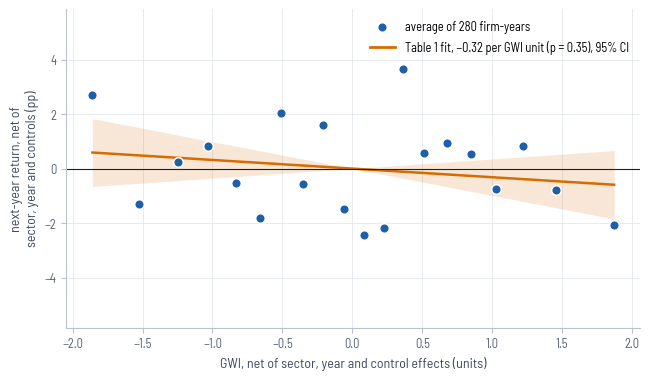

In [13]:
# Figure 4 of the memo: binned scatter of the Table 1 regression (Frisch-Waugh-Lovell)
def fwl(m, term):
    """The regressor and the outcome net of all other regressors of model m (Frisch-Waugh-Lovell)."""
    X, names = m.model.exog, m.model.exog_names
    j = names.index(term)
    Q, _ = np.linalg.qr(np.delete(X, j, axis=1))
    x, yv = X[:, j], m.model.endog
    return x - Q @ (Q.T @ x), yv - Q @ (Q.T @ yv)


xt, yt = fwl(h1, 'gwi')
assert abs((xt @ yt) / (xt @ xt) - b1) < 1e-10               # the slope in this picture is exactly the Table 1 coefficient
bins = pd.DataFrame({'x': xt, 'y': yt, 'bin': pd.qcut(pd.Series(xt).rank(method='first'), 20, labels=False)})
bn = bins.groupby('bin').agg(x=('x', 'mean'), y=('y', 'mean'), n=('y', 'size'))
print(f'{len(xt):,} firm-years in {len(bn)} groups of {bn.n.iloc[0]}')
fig, ax = plt.subplots(figsize=(6.5, 3.8))
xs = np.linspace(bn.x.min(), bn.x.max(), 200)
ax.fill_between(xs, b1 * xs - 1.96 * se1 * np.abs(xs), b1 * xs + 1.96 * se1 * np.abs(xs), color=ORANGE, alpha=.16, lw=0)
ax.plot(xs, b1 * xs, color=ORANGE, lw=1.8)
ax.scatter(bn.x, bn.y, s=48, color=BLUE, zorder=3, **RING, label=f'average of {bn.n.iloc[0]} firm-years')
ax.plot([], [], color=ORANGE, lw=2, label=f"Table 1 fit, {fmt(b1)} per GWI unit (p = {h1.pvalues['gwi']:.2f}), 95% CI")
ax.axhline(0, color=INK, lw=0.8)
lim = max(abs(bn.y).max(), 1) * 1.6
ax.set_ylim(-lim, lim)
ax.set_xlabel('GWI, net of sector, year and control effects (units)')
ax.set_ylabel('next-year return, net of\nsector, year and controls (pp)')
ax.legend(loc='upper right')
save_figure(fig, 'figure4_h1_binned_scatter.png')

**What we find.** H1 is not supported. One GWI unit goes with 0.32 pp lower next-year return, but the standard error is 0.34 (p = 0.35). Between the top and bottom fifth that is 0.9 pp a year, with a 95% range from a 2.8 pp penalty to a 1.0 pp reward. Figure 4 shows why: once sector, year and the controls are removed, the 20 group averages scatter around zero with no visible slope. The test is not simply weak, though: a penalty of 1 pp or more per GWI unit (2.8 pp a year top versus bottom) is rejected (one-sided p = 0.023).

Returns are explained by fundamentals rather than by the gap: ROA (p = 0.020) and leverage (p = 0.025) matter, size does not, and the whole model explains 21.4% of the variation against 21.1% for the fixed effects alone. Talk and Walk entered separately both point the way the greenwashing story predicts (more talk, lower return; cleaner, higher return) but neither is distinguishable from zero, so the null is not a carbon premium hidden inside the index. The two-year window widens the top-versus-bottom gap to 3.4 pp, which hints at slow repricing, but p = 0.11, or 0.32 after the Holm correction.

## 6. H2: did the penalty grow after the Paris Agreement? (memo 5.2, Table 2, Figure 5)
H2 adds GWI × PostParis, where PostParis = 1 for 10-K years from 2016. PostParis on its own is absorbed by the year fixed effects. Because the Agreement affected every firm at once there is no control group, so the change in the slope is read descriptively, not causally. Two variants test how fragile the answer is: dropping 2010, the year with the largest pre-Paris estimate, and counting the 2015 10-Ks (filed in early 2016) as post-Paris. A second model estimates one GWI slope per 10-K year and tests them jointly with Wald tests on the clustered covariance matrix (chi-squared tests; the memo calls the pre-trend test an F-test).

In [14]:
h2 = fit('ret', ['gwi', 'gwi:post'] + CTRL, base)
after = h2.t_test('gwi + gwi:post = 0')
after_b, after_se, after_p = (np.asarray(v).item() for v in (after.effect, after.sd, after.pvalue))
h2_mde = (stats.norm.ppf(.975) + stats.norm.ppf(.8)) * h2.bse['gwi:post']
h2_no2010 = fit('ret', ['gwi', 'gwi:post'] + CTRL, base[base.year > 2010])
h2_2015 = fit('ret', ['gwi', 'gwi:post15'] + CTRL, base.assign(post15=(base.year >= 2015).astype(int)))
print(f"Slope 2010-15: {fmt(h2.params['gwi'])} (p = {h2.pvalues['gwi']:.3f}); change after Paris "
      f"{fmt(h2.params['gwi:post'])} (p = {h2.pvalues['gwi:post']:.3f}); slope 2016-24 {fmt(after_b)} (p = {after_p:.3f})")
print(f"Top vs bottom fifth: {abs(h2.params['gwi'] * q5):.1f} pp a year below before Paris, {abs(after_b * q5):.1f} pp after")
print(f'Power: a change of {h2_mde * q5:.1f} pp a year in the top-vs-bottom gap would be detected 80% of the time')
print(f"Without 2010: change {fmt(h2_no2010.params['gwi:post'])} (p = {h2_no2010.pvalues['gwi:post']:.2f}, "
      f'N = {int(h2_no2010.nobs):,}); 2015 10-Ks as post-Paris: change {fmt(h2_2015.params["gwi:post15"])} '
      f"(p = {h2_2015.pvalues['gwi:post15']:.2f})")

# one GWI slope per 10-K year, in one pooled model
yr = smf.ols(f"ret ~ gwi:C(year) + {' + '.join(CTRL)} + {FE}", data=base).fit(
    cov_type='cluster', cov_kwds={'groups': base['entity_code']})
years = list(range(2010, 2025))
names = [f'gwi:C(year)[{y}]' for y in years]
Y = pd.DataFrame({'year': years, 'coef': yr.params[names].values, 'se': yr.bse[names].values, 'p': yr.pvalues[names].values})


def wald(rows):
    pos = {n: i for i, n in enumerate(yr.params.index)}
    R = np.zeros((len(rows), len(pos)))
    for j, row in enumerate(rows):
        for n, w in row.items():
            R[j, pos[n]] = w
    return float(yr.wald_test(R, scalar=True).pvalue)


pre = [n for n, y in zip(names, years) if y < 2016]
p_all_equal = wald([{names[j]: 1, names[j + 1]: -1} for j in range(len(names) - 1)])   # 14 restrictions
p_all_zero = wald([{n: 1} for n in names])                                             # 15 restrictions
p_pre_equal = wald([{pre[j]: 1, pre[j + 1]: -1} for j in range(len(pre) - 1)])          # 5 restrictions (2010-15)
print(f'Joint Wald tests: six pre-Paris slopes (2010-15) equal p = {p_pre_equal:.2f}; all 15 equal p = {p_all_equal:.2f}; '
      f'all 15 zero p = {p_all_zero:.2f}; every yearly 95% range includes zero: '
      f'{bool(((Y.coef - 1.96 * Y.se) < 0).all() and ((Y.coef + 1.96 * Y.se) > 0).all())}')

Slope 2010-15: −0.66 (p = 0.232); change after Paris +0.50 (p = 0.466); slope 2016-24 −0.16 (p = 0.716)
Top vs bottom fifth: 1.9 pp a year below before Paris, 0.4 pp after
Power: a change of 5.5 pp a year in the top-vs-bottom gap would be detected 80% of the time
Without 2010: change +0.25 (p = 0.73, N = 5,311); 2015 10-Ks as post-Paris: change +1.11 (p = 0.15)
Joint Wald tests: six pre-Paris slopes (2010-15) equal p = 0.36; all 15 equal p = 0.52; all 15 zero p = 0.50; every yearly 95% range includes zero: True


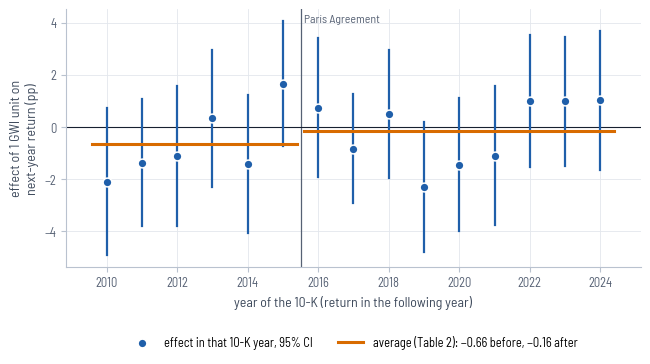

In [15]:
# Figure 5 of the memo: the GWI slope year by year
fig, ax = plt.subplots(figsize=(6.5, 3.7))
ax.axvline(2015.5, color=MUTED, lw=0.9)
ax.text(2015.6, 0.98, 'Paris Agreement', transform=ax.get_xaxis_transform(), fontsize=8.5, color=MUTED, va='top')
ax.axhline(0, color=INK, lw=0.8)
for _, r in Y.iterrows():
    ax.plot([r.year, r.year], [r.coef - 1.96 * r.se, r.coef + 1.96 * r.se], color=BLUE, lw=1.6)
ax.scatter(Y.year, Y.coef, s=40, color=BLUE, zorder=3, **RING, label='effect in that 10-K year, 95% CI')
ax.plot([2009.6, 2015.4], [h2.params['gwi']] * 2, color=ORANGE, lw=2.2,
        label=f"average (Table 2): {fmt(h2.params['gwi'])} before, {fmt(after_b)} after")
ax.plot([2015.6, 2024.4], [after_b] * 2, color=ORANGE, lw=2.2)
ax.set_xticks(range(2010, 2025, 2))
ax.set_xlabel('year of the 10-K (return in the following year)')
ax.set_ylabel('effect of 1 GWI unit on\nnext-year return (pp)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2)
save_figure(fig, 'figure5_h2_yearly_effects.png')

**What we find.** H2 is not supported, and the estimate points the other way. The GWI slope is −0.66 for 10-Ks of 2010-15 and −0.16 for 2016-24, so the top-versus-bottom gap shrinks from about 1.9 to 0.4 pp a year; the change (+0.50) has p = 0.47. Even that shrinkage is fragile: it rests largely on 2010, and without that year the change halves to +0.25 (p = 0.73), while counting the 2015 10-Ks as post-Paris gives +1.11 (p = 0.15). Figure 5 shows no break at Paris: every year's range includes zero, the six pre-Paris slopes do not differ from each other (p = 0.36), and the 15 slopes are neither different from one another (p = 0.52) nor jointly different from zero (p = 0.50). The design has limited power here: only a change of about 5 pp a year in the top-versus-bottom gap would be detected reliably.

## 7. Reaction to the 10-K filing (memo 5.3, Table 2)
A full year of returns may bury a small reaction, and the filing day is when investors first see a firm's Talk. We therefore regress the abnormal return over the filing day and the next two trading days on GWI with the same controls and fixed effects. The test was added after the annual test found nothing, but its design was written down before any filing-day returns were computed. Since this is a second test of the same hypothesis, its p-value is Holm-adjusted together with the annual test.

In [16]:
ev = P.dropna(subset=['gwi', 'car_0_2_w'] + CTRL)
e1 = fit('car_0_2_w', ['gwi'] + CTRL, ev)
e2 = fit('car_0_2_w', ['gwi', 'gwi:post'] + CTRL, ev)
holm2 = multipletests([h1.pvalues['gwi'], e1.pvalues['gwi']], method='holm')[1]
print(f"Filing reaction: {e1.params['gwi']:.3f} pp per GWI unit, s.e. {e1.bse['gwi']:.3f}, t = {e1.tvalues['gwi']:.2f}, "
      f"p = {e1.pvalues['gwi']:.3f}, Holm p (two return tests) = {holm2[1]:.3f}, N = {int(e1.nobs):,} filings")
print(f"Top vs bottom fifth: {e1.params['gwi'] * q5:.2f} pp over the three days; change after Paris "
      f"{fmt(e2.params['gwi:post'], 3)} (p = {e2.pvalues['gwi:post']:.2f})")

rows2 = [('Annual return: before Paris (10-Ks 2010-15)', h2.params['gwi'], h2.bse['gwi'], h2.pvalues['gwi'], 2),
         ('Annual return: change after Paris', h2.params['gwi:post'], h2.bse['gwi:post'], h2.pvalues['gwi:post'], 2),
         ('Annual return: after Paris (10-Ks 2016-24)', after_b, after_se, after_p, 2),
         ('Change after Paris, excluding 2010', h2_no2010.params['gwi:post'], h2_no2010.bse['gwi:post'], h2_no2010.pvalues['gwi:post'], 2),
         ('Change after Paris, 2015 10-Ks counted as post-Paris', h2_2015.params['gwi:post15'], h2_2015.bse['gwi:post15'], h2_2015.pvalues['gwi:post15'], 2),
         ('3-day filing reaction (vs S&P 500)', e1.params['gwi'], e1.bse['gwi'], e1.pvalues['gwi'], 3),
         ('3-day filing reaction: change after Paris', e2.params['gwi:post'], e2.bse['gwi:post'], e2.pvalues['gwi:post'], 3)]
table2 = pd.DataFrame([(lab, fmt(c, d), f'{s:.{d}f}', f'{p:.3f}', fmt(c * q5)) for lab, c, s, p, d in rows2],
                      columns=['Estimate', 'Per GWI unit', 'Std. err.', 'p', 'Top vs bottom fifth']).set_index('Estimate')
print('\nTable 2. H2 and the 10-K filing reaction')
display(table2)
print(f'Annual returns: N = {int(h2.nobs):,} ({int(h2_no2010.nobs):,} without 2010). Filing reaction: N = {int(e1.nobs):,} '
      f'filings; p = {holm2[1]:.3f} after Holm correction for two return tests.')

Filing reaction: -0.087 pp per GWI unit, s.e. 0.044, t = -1.95, p = 0.051, Holm p (two return tests) = 0.101, N = 5,610 filings
Top vs bottom fifth: -0.25 pp over the three days; change after Paris +0.055 (p = 0.52)

Table 2. H2 and the 10-K filing reaction


,Per GWI unit,Std. err.,p,Top vs bottom fifth
Estimate,,,,
Annual return: before Paris (10-Ks 2010-15),−0.66,0.55,0.232,−1.86
Annual return: change after Paris,+0.50,0.69,0.466,+1.42
Annual return: after Paris (10-Ks 2016-24),−0.16,0.43,0.716,−0.44
"Change after Paris, excluding 2010",+0.25,0.71,0.730,+0.70
"Change after Paris, 2015 10-Ks counted as post-Paris",+1.11,0.78,0.153,+3.13
3-day filing reaction (vs S&P 500),−0.087,0.044,0.051,−0.25
3-day filing reaction: change after Paris,+0.055,0.085,0.522,+0.15


Annual returns: N = 5,600 (5,311 without 2010). Filing reaction: N = 5,610 filings; p = 0.101 after Holm correction for two return tests.


**What we find.** There is at most a weak dip. Over the three days the top GWI fifth trails the bottom fifth by 0.25 pp relative to the S&P 500 (−0.087 per GWI unit, p = 0.051). That is borderline on its own and not significant once corrected for running two return tests (p = 0.101), and it is no larger after Paris (p = 0.52). The direction fits investors noticing the gap, but the size is far too small and fragile to trade on; one reason may be that emissions are usually published months after the 10-K.

## 8. Robustness (memo 5.4, Table 3)
A null result is only informative if it does not hinge on one modelling choice. Each row of Table 3 changes one choice in the Table 1 model:
* *controls*: none at all, or adding book-to-market (book equity ÷ market value at the end of year t) and the past-year return;
* *how Walk is measured*: adding LSEG's firm-specific CO2-model estimates for firms that do not report (estimates based on industry medians or energy use are not used), or replacing Walk with the LSEG Environmental Pillar rank;
* *how Talk is measured*: FinBERT only, or Loughran-McDonald only;
* *peer groups*: ranking within Fama-French 12 industries instead of TRBC sectors, or one fixed effect per sector-year pair;
* *timing*: returns from April of t+1 to March of t+2, for 10-Ks filed before April, so the window opens only once the 10-K is public;
* *sample and estimator*: excluding financial firms, and Fama-MacBeth (one regression per year, averaging the 15 slopes so shocks common to a year cannot drive the result).

In [17]:
def gwi_row(label, col, y='ret', data=None, ctrl=CTRL, fe=FE):
    d = (P if data is None else data).copy()
    d['g'] = d[col]
    m = fit(y, ['g'] + ctrl, d, fe=fe)
    lo_, hi_ = m.conf_int().loc['g']
    return dict(check=label, effect=m.params['g'], se=m.bse['g'], p=m.pvalues['g'], ci_low=lo_, ci_high=hi_, n=int(m.nobs))


april = P[P.filing_date < pd.to_datetime((P.year + 1).astype(str) + '-04-01')]
rows = [gwi_row('Main model (Table 1)', 'gwi'),
        gwi_row('No size, ROA or leverage controls', 'gwi', ctrl=[], data=base),
        gwi_row('Adding book-to-market and past-year return', 'gwi', ctrl=CTRL + ['bm_w', 'mom_w']),
        gwi_row('Walk adds LSEG estimates for non-reporters', 'gwi_est'),
        gwi_row('Walk = LSEG Environmental Pillar rank', 'gwi_ep'),
        gwi_row('Peers = Fama-French 12 industries', 'gwi_ff12'),
        gwi_row('Talk from FinBERT only', 'gwi_fb'),
        gwi_row('Talk from Loughran-McDonald only', 'gwi_lm'),
        gwi_row('Return from April, after the 10-K is public', 'gwi', y='ret_am', data=april),
        gwi_row('Excluding financial firms', 'gwi', data=P[P.trbc != '55']),
        gwi_row('Sector-by-year fixed effects', 'gwi', fe='C(sector_year)')]
fm_b = np.array([smf.ols(f"ret ~ gwi + {' + '.join(CTRL)} + C(trbc)", data=d).fit().params['gwi']
                 for _, d in base.groupby('year')])                      # Fama-MacBeth: one regression per year
fm_se = fm_b.std(ddof=1) / np.sqrt(len(fm_b))
crit = stats.t.ppf(.975, len(fm_b) - 1)
rows.append(dict(check='Fama-MacBeth (one regression per year, averaged)', effect=fm_b.mean(), se=fm_se,
                 p=2 * stats.t.sf(abs(fm_b.mean() / fm_se), len(fm_b) - 1),
                 ci_low=fm_b.mean() - crit * fm_se, ci_high=fm_b.mean() + crit * fm_se, n=len(base)))
rob = pd.DataFrame(rows).set_index('check')
table3 = pd.DataFrame({'Per GWI unit': rob.effect.map(fmt), 'p': rob.p.map(lambda v: f'{v:.2f}'),
                       'N': rob.n.map(lambda v: f'{v:,}')})
print('Table 3. Robustness: effect of GWI on next-year return under alternative specifications')
display(table3)
others = rob.drop(['Main model (Table 1)', 'Return from April, after the 10-K is public'])
print(f'{len(rob) - 1} alternatives; smallest p = {rob.p.iloc[1:].min():.2f}; apart from the April window the effect stays '
      f'between {others.effect.max():.2f} and {others.effect.min():.2f}; multiply by {q5:.2f} for the top-vs-bottom gap')

Table 3. Robustness: effect of GWI on next-year return under alternative specifications


,Per GWI unit,p,N
check,,,
Main model (Table 1),−0.32,0.35,"5,600"
"No size, ROA or leverage controls",−0.42,0.23,"5,600"
Adding book-to-market and past-year return,−0.38,0.27,"5,359"
Walk adds LSEG estimates for non-reporters,−0.29,0.39,"5,934"
Walk = LSEG Environmental Pillar rank,−0.08,0.79,"6,999"
Peers = Fama-French 12 industries,−0.33,0.39,"5,588"
Talk from FinBERT only,−0.46,0.18,"5,600"
Talk from Loughran-McDonald only,−0.22,0.52,"5,600"
"Return from April, after the 10-K is public",+0.18,0.63,"5,562"


11 alternatives; smallest p = 0.18; apart from the April window the effect stays between -0.08 and -0.46; multiply by 2.82 for the top-vs-bottom gap


### 8.1 Further checks (not in Table 3)
Nine more versions from our original analysis, which the memo summarises in one sentence. GWI variants are rebuilt from their inputs with the rules of section 2.2; rebuilding the pillar version of Table 3 the same way reproduces it exactly, which shows the rebuild is faithful.
* *Walk = pillar rank on the main-sample rows*; *Walk = the raw pillar score* instead of its rank;
* *LSEG revenue as delivered*, before the as-filed fix of the data audit (memo 4.1);
* *at least 10 firms per sector-year* instead of 5; *size = ln(total assets)*;
* *firms present before and after 2016* only; *unwinsorised returns*;
* *two-way clustering* by company and year (unreliable with only 15 years, so a check rather than an alternative);
* *Yahoo returns only*, for the firms Yahoo still covers.

In [18]:
def build_gwi(walk_input, higher_is_better=False, min_n=5):
    """Talk and GWI from the raw Talk measures and a Walk input, with the rules of section 2.2."""
    ok = P.fb_talk_raw.notna() & P.lm_talk_raw.notna() & walk_input.notna() & P.trbc.notna()
    d = P[ok]
    d = d[d.groupby(['trbc', 'year'])['firm_id'].transform('size') >= min_n]
    gg = [d['trbc'], d['year']]
    talk = pct((pct(d.fb_talk_raw, gg) + pct(d.lm_talk_raw, gg)) / 2, gg)
    w = pct(walk_input[d.index], gg)
    gap = talk - (w if higher_is_better else 100 - w)
    return talk.reindex(P.index), ((gap - gap.mean()) / gap.std()).reindex(P.index)


talk_ep, gwi_ep_check = build_gwi(P.ep, higher_is_better=True)
assert (gwi_ep_check - P.gwi_ep).abs().max() < 1e-9
gap = talk_ep - P.ep
P['gwi_epraw'] = (gap - gap.mean()) / gap.std()
P['gwi_lsegrev'] = build_gwi(P.s12 / P.rev_lseg.where(P.rev_lseg > 0))[1]
P['gwi_min10'] = build_gwi(P.ci, min_n=10)[1]
P['ret_raw'] = P.ret_cy * 100
P['ret_y'] = P.ret_cy_yahoo.clip(*P.ret_cy_yahoo.quantile([.01, .99])) * 100
both_sides = P.groupby('entity').year.transform(lambda s: (s.min() < 2016) & (s.max() >= 2016))
tw = smf.ols(f"ret ~ gwi + {' + '.join(CTRL)} + {FE}", data=base).fit(
    cov_type='cluster', cov_kwds={'groups': np.column_stack([pd.factorize(base.entity)[0], pd.factorize(base.year)[0]])})
more = pd.DataFrame([
    gwi_row('Walk = pillar rank on main-sample rows', 'gwi_epm'),
    gwi_row('Walk = raw pillar score (not ranked)', 'gwi_epraw'),
    gwi_row('LSEG revenue as delivered', 'gwi_lsegrev'),
    gwi_row('At least 10 firms per sector-year', 'gwi_min10'),
    gwi_row('Size = ln(total assets)', 'gwi', ctrl=['size_assets_w', 'roa_w', 'lev_w']),
    gwi_row('Firms present before and after 2016', 'gwi', data=P[both_sides]),
    gwi_row('Unwinsorised return', 'gwi', y='ret_raw'),
    dict(check='Two-way clustering (company and year)', effect=tw.params['gwi'], se=tw.bse['gwi'], p=tw.pvalues['gwi'],
         ci_low=tw.conf_int().loc['gwi', 0], ci_high=tw.conf_int().loc['gwi', 1], n=int(tw.nobs)),
    gwi_row('Yahoo returns only', 'gwi', y='ret_y'),
]).set_index('check')
display(more.round(3))
print(f'None is significant: smallest p = {more.p.min():.2f} ({more.p.idxmin()})')

,effect,se,p,ci_low,ci_high,n
check,,,,,,
Walk = pillar rank on main-sample rows,-0.207,0.351,0.555,-0.896,0.481,5600
Walk = raw pillar score (not ranked),-0.019,0.315,0.953,-0.635,0.598,6999
LSEG revenue as delivered,-0.279,0.343,0.416,-0.951,0.393,5600
At least 10 firms per sector-year,-0.325,0.344,0.345,-0.998,0.349,5594
Size = ln(total assets),-0.347,0.344,0.313,-1.021,0.327,5600
Firms present before and after 2016,-0.478,0.350,0.172,-1.164,0.209,4793
Unwinsorised return,-0.267,0.369,0.469,-0.990,0.456,5600
Two-way clustering (company and year),-0.317,0.319,0.320,-0.941,0.307,5600
Yahoo returns only,-0.342,0.352,0.331,-1.033,0.348,5046


None is significant: smallest p = 0.17 (Firms present before and after 2016)


**What we find.** The null is robust. None of the eleven alternatives is significant (smallest p = 0.18, FinBERT-only Talk), and the estimates are stable: apart from the April window the effect stays between −0.08 and −0.46 per GWI unit, against −0.32 in the main model. Adding valuation and momentum moves it only to −0.38, so the null is not explained by those known return patterns. Starting returns in April, once the 10-K is public, flips the sign to +0.18 (p = 0.63), which again says the gap is not priced. The nine further checks give the same answer (smallest p = 0.17); using LSEG revenue exactly as delivered barely changes the estimate (−0.28, p = 0.42).

## 9. What the ESG rating rewards (memo 5.5, Table 4)
The memo's problem statement assumes that ratings reward what firms say. We test that directly with LSEG's Environmental Pillar score: how it relates to our emissions-based Walk and to Talk, how much it rewards the mere act of reporting emissions, and whether a GWI built on the rating would flag the same firms. The reporting comparison needs firms that do not report emissions, so it uses every firm-year with a pillar score, ranked within sector and year as rank ÷ n × 100, and controls for size with ln(total assets). Both comparisons hold sector and year fixed, so industry cannot explain the result.

In [19]:
rho_rating_walk = gs[['walk_epm', 'walk']].corr('spearman').iloc[0, 1]
rho_rating_talk = gs[['talk_epm', 'walk_epm']].corr('spearman').iloc[0, 1]
e = P.dropna(subset=['ep', 'trbc']).copy()
e['reports'] = e['scope12_reported'].notna().astype(int)
e['ep_pct'] = e.groupby(['trbc', 'year'])['ep'].rank(pct=True) * 100
gap_rep = fit('ep_pct', ['reports'], e)
gap_rep2 = fit('ep_pct', ['reports', 'size_assets_w'], e)
on = fit('walk_epm', ['talk_epm', 'walk'], gs)
q1, q2 = gs.gwi >= gs.gwi.quantile(.8), gs.gwi_epm >= gs.gwi_epm.quantile(.8)
overlap = (q1 & q2).sum() / q1.sum()
table4 = pd.DataFrame([
    ('Correlation: rating vs emissions-based Walk', fmt(rho_rating_walk)),
    ('Correlation: rating vs Talk', fmt(rho_rating_talk)),
    ('Correlation: Talk vs emissions-based Walk', fmt(rho_tw)),
    ('Rating gap, emission reporters minus non-reporters (same sector-year)',
     f"{fmt(gap_rep.params['reports'], 1)} points (t = {gap_rep.tvalues['reports']:.1f})"),
    ('Same gap, allowing for firm size', f"{fmt(gap_rep2.params['reports'], 1)} points"),
    ('Rating change for +50 ranks of Talk, emissions held fixed',
     f"{fmt(50 * on.params['talk_epm'], 1)} points (t = {on.tvalues['talk_epm']:.1f})"),
    ('Rating change for +50 ranks of Walk (cleaner), Talk held fixed',
     f"{fmt(50 * on.params['walk'], 1)} points (t = {on.tvalues['walk']:.1f})"),
    ('Top-fifth carbon greenwashers also top fifth under rating-based GWI', f'{overlap:.0%}'),
], columns=['Statistic', 'Value']).set_index('Statistic')
print('Table 4. What the LSEG environmental rating tracks')
display(table4)
print(f'Spearman rank correlations, N = {len(gs):,} firm-years (reporter gap: {int(gap_rep.nobs):,})')
r_ep = rob.loc['Walk = LSEG Environmental Pillar rank']
print(f'Using the rating as Walk changes the return result little: {fmt(r_ep.effect)} per GWI unit, p = {r_ep.p:.2f}')

Table 4. What the LSEG environmental rating tracks


,Value
Statistic,
Correlation: rating vs emissions-based Walk,−0.07
Correlation: rating vs Talk,+0.16
Correlation: Talk vs emissions-based Walk,−0.17
"Rating gap, emission reporters minus non-reporters (same sector-year)",+37.3 points (t = 26.0)
"Same gap, allowing for firm size",+31.3 points
"Rating change for +50 ranks of Talk, emissions held fixed",+7.9 points (t = 5.1)
"Rating change for +50 ranks of Walk (cleaner), Talk held fixed",−2.0 points (t = -1.2)
Top-fifth carbon greenwashers also top fifth under rating-based GWI,43%


Spearman rank correlations, N = 5,635 firm-years (reporter gap: 7,059)
Using the rating as Walk changes the return result little: −0.08 per GWI unit, p = 0.79


**What we find.** This is the memo's strongest result. The rating is essentially unrelated to emissions-based Walk (Spearman −0.07) but positively related to Talk (+0.16). Disclosure is the clearest driver: within the same sector and year, firms that report emissions rank 37 percentile points higher than firms that do not (t = 26), and still 31 points higher after allowing for size, whatever the reported numbers show. Holding emissions fixed, 50 more ranks of Talk lift the rating by 7.9 points (t = 5.1); holding Talk fixed, 50 ranks cleaner changes it by −2.0 points, which is not significant. Since firms that talk more tend to be dirtier (−0.17), a rating that rewards talk partly rewards the firms with the largest gap, and only 43% of our top-fifth greenwashers stay in the top fifth if the rating replaces Walk. For an allocator, a rating-based screen inherits this bias, which is the basis of the memo's first two recommendations. One caveat: size is controlled in the reporting comparison but not in the Talk regression.

## 10. Sectors (exploratory; memo 5.6, Figure 6)
A pooled null could hide an effect in a few industries. This split was not in our proposal, so we fixed the method and a decision rule in writing before running it. A sector counts as a finding only if its Holm-adjusted p is below 0.05 (or a shuffle test is), its sign is the same in 2010-16 and 2017-24, and no single firm flips the sign when left out.

The model gives every sector its own GWI slope in one regression, with the controls, sector and year fixed effects. Two corrections guard against reading noise as a result: the Holm correction for testing many sectors, and a shuffle (permutation) test that reshuffles GWI within each sector-year 1,000 times (seed 5324) and asks how often *some* sector looks at least as strong as the strongest real one. We first use the 10 TRBC economic sectors, then 22 business-sector groups (business sectors with fewer than 100 firm-years are pooled into "<economic sector> - other").

In [20]:
SEC_NAMES = {'50': 'Energy', '51': 'Basic Materials', '52': 'Industrials', '53': 'Consumer Cyclicals',
             '54': 'Consumer Non-Cyclicals', '55': 'Financials', '56': 'Healthcare', '57': 'Technology',
             '59': 'Utilities', '60': 'Real Estate'}


def slope_model(d, gcol, fe_col=None):
    """ret ~ sum over groups of GWI x 1[group] + controls + group FE + year FE (SE clustered by company)."""
    fe_col = fe_col or gcol
    groups = sorted(d[gcol].unique())
    est = [g for g in groups if (d[gcol] == g).sum() >= 2 and d.loc[d[gcol] == g, 'gwi'].nunique() > 1]
    d = d.copy()
    cols = []
    for g in est:
        d[f's_{g}'] = d['gwi'] * (d[gcol] == g)
        cols.append(f's_{g}')
    m = smf.ols(f"ret ~ {' + '.join(cols)} + {' + '.join(CTRL)} + C({fe_col}) + C(year)", data=d).fit(
        cov_type='cluster', cov_kwds={'groups': d['entity_code']})
    return m, est, cols


class Shuffle:
    """Fast re-estimation of the slope t-statistics for shuffled GWI (Frisch-Waugh-Lovell): the controls and fixed
    effects are partialled out once; the clustered covariance matches statsmodels (same small-sample factor)."""

    def __init__(self, m, d, gcol, est, cols):
        names = m.model.exog_names
        idx_s = [names.index(c) for c in cols]
        W = m.model.exog[:, [i for i in range(len(names)) if i not in idx_s]]
        self.Q, _ = np.linalg.qr(W)
        yv = m.model.endog
        self.yt = yv - self.Q @ (self.Q.T @ yv)
        self.D = np.column_stack([(d[gcol] == g).to_numpy(float) for g in est])
        codes = pd.factorize(d['entity_code'])[0]
        G = codes.max() + 1
        self.C = sparse.csr_matrix((np.ones(len(d)), (codes, np.arange(len(d)))), shape=(G, len(d)))
        self.fact = G / (G - 1) * (len(d) - 1) / (len(d) - len(names))

    def t(self, gwi):
        X = gwi[:, None] * self.D
        Xt = X - self.Q @ (self.Q.T @ X)
        XtX_inv = np.linalg.inv(Xt.T @ Xt)
        b = XtX_inv @ (Xt.T @ self.yt)
        res = self.yt - Xt @ b
        S = self.C @ (Xt * res[:, None])
        return b / np.sqrt(np.diag(self.fact * XtX_inv @ (S.T @ S) @ XtX_inv))


def shuffle_t(sh, d, n=N_SHUFFLE, seed=SEED):
    """t-statistics of n shuffles of GWI within economic sector-year."""
    strata = pd.factorize(d['sector_year'])[0]
    rng = np.random.default_rng(seed)
    g0, T = d['gwi'].to_numpy(), np.empty((n, sh.D.shape[1]))
    dst = np.argsort(strata, kind='stable')
    for r in range(n):
        # rows sorted by sector-year (dst) take the GWI of the same sector-year's rows in random order (src)
        src = np.lexsort((rng.random(len(strata)), strata))
        idx = np.empty(len(strata), dtype=int)
        idx[dst] = src
        T[r] = sh.t(g0[idx])
    return T


def sector_table(d, gcol, labels):
    m, est, cols = slope_model(d, gcol)
    T = shuffle_t(Shuffle(m, d, gcol, est, cols), d)
    t_obs = m.tvalues[cols].to_numpy()
    out = pd.DataFrame({'group': [labels[g] for g in est], 'effect': m.params[cols].values, 'se': m.bse[cols].values,
                        'p': m.pvalues[cols].values, 'p_holm': multipletests(m.pvalues[cols], method='holm')[1],
                        'p_shuffle_own': (np.abs(T) >= np.abs(t_obs)).mean(axis=0),
                        'n': [int((d[gcol] == g).sum()) for g in est]}, index=est)
    p_shuffle = float((np.abs(T).max(axis=1) >= np.abs(t_obs).max()).mean())
    return out.sort_values('effect'), p_shuffle, m, cols


s10, p10_shuffle, m10, _ = sector_table(base, 'trbc', SEC_NAMES)
print('GWI effect by TRBC economic sector (10 sectors)')
display(s10.round(3))
print(f'Shuffle test (largest |t| of 10 sectors): p = {p10_shuffle:.2f}')

cnt = base.groupby('trbc_business').size()
POOL = 100                                                 # business sectors below 100 firm-years are pooled
base['bs'] = np.where(base.trbc_business.map(cnt) >= POOL, base.trbc_business.astype(str), base.trbc + 'xx')
labels = {g: (SEC_NAMES[g[:2]] + ' - other' if g.endswith('xx') else
              base.loc[base.bs == g, 'trbc_business_name'].iloc[0]) for g in base.bs.unique()}
s22, p22_shuffle, m22, cols22 = sector_table(base, 'bs', labels)
print(f'\nGWI effect by TRBC business sector ({len(s22)} groups)')
display(s22.round(4))
print(f'Shuffle test (largest |t| of {len(s22)} groups): p = {p22_shuffle:.2f}')

GWI effect by TRBC economic sector (10 sectors)


,group,effect,se,p,p_holm,p_shuffle_own,n
51,Basic Materials,-2.595,1.178,0.028,0.276,0.037,353
57,Technology,-1.501,1.113,0.177,1.000,0.166,889
56,Healthcare,-1.143,0.924,0.216,1.000,0.195,643
54,Consumer Non-Cyclicals,-0.355,1.038,0.732,1.000,0.729,523
53,Consumer Cyclicals,-0.142,0.923,0.878,1.000,0.868,743
52,Industrials,0.051,0.774,0.947,1.000,0.943,772
59,Utilities,0.332,0.838,0.692,1.000,0.642,385
55,Financials,0.582,0.801,0.468,1.000,0.410,606
60,Real Estate,0.707,1.173,0.546,1.000,0.488,310
50,Energy,2.266,2.229,0.309,1.000,0.197,376


Shuffle test (largest |t| of 10 sectors): p = 0.18



GWI effect by TRBC business sector (22 groups)


,group,effect,se,p,p_holm,p_shuffle_own,n
57xx,Technology - other,-6.9776,4.2664,0.1019,1.0000,0.181,78
51xx,Basic Materials - other,-4.5893,2.3166,0.0476,0.9517,0.088,160
5620,Pharmaceuticals & Medical Research,-4.5629,1.0498,0.0000,0.0003,0.000,257
5710,Technology Equipment,-3.6231,1.7680,0.0404,0.8491,0.034,453
5410,Food & Beverages,-1.8783,1.0416,0.0714,1.0000,0.076,322
5110,Chemicals,-1.7306,1.5550,0.2658,1.0000,0.273,193
5320,Cyclical Consumer Products,-1.4970,2.3076,0.5165,1.0000,0.528,149
5330,Cyclical Consumer Services,-1.0197,1.1386,0.3705,1.0000,0.360,262
5240,Transportation,-0.3624,1.2542,0.7726,1.0000,0.770,178
5720,Software & IT Services,0.0984,1.7619,0.9555,1.0000,0.962,358


Shuffle test (largest |t| of 22 groups): p = 0.12


**Pharmaceuticals & Medical Research** is the one group that meets the rule. The next cell tests the rule's three conditions and then asks where the effect comes from: each firm-year's contribution to the slope (Frisch-Waugh-Lovell; the contributions add up to the slope), grouped by business type, and what happens once business models are allowed for. The business types are our own hand coding from public company descriptions.

In [21]:
G = '5620'
ph = s22.loc[G]
print(f"Pharma: {ph.effect:+.2f} per GWI unit (p = {ph.p:.1e}, Holm p = {ph.p_holm:.4f}), {base.bs.eq(G).sum()} firm-years, "
      f"{base.loc[base.bs.eq(G), 'firm_id'].nunique()} firms")


def pharma_model(d, split=None):
    d = d.copy()
    cols = [f's_{g}' for g in sorted(d.bs.unique()) if g != G]
    for g in sorted(d.bs.unique()):
        if g != G:
            d[f's_{g}'] = d.gwi * (d.bs == g)
    if split is None:
        d['s_G'] = d.gwi * (d.bs == G); cols.append('s_G')
    else:
        d['s_G_early'] = d.gwi * (d.bs == G) * (d.year <= 2016)
        d['s_G_late'] = d.gwi * (d.bs == G) * (d.year >= 2017); cols += ['s_G_early', 's_G_late']
    return smf.ols(f"ret ~ {' + '.join(cols)} + {' + '.join(CTRL)} + C(bs) + C(year)", data=d).fit(
        cov_type='cluster', cov_kwds={'groups': pd.factorize(d['entity'])[0]})


mh = pharma_model(base, split=True)
print(f"Same sign in both halves: 2010-16 {mh.params['s_G_early']:+.2f} (p = {mh.pvalues['s_G_early']:.3f}), "
      f"2017-24 {mh.params['s_G_late']:+.2f} (p = {mh.pvalues['s_G_late']:.3f})")
lofo = pd.Series({f: pharma_model(base[base.firm_id != f]).params['s_G']
                  for f in sorted(base.loc[base.bs.eq(G), 'firm_id'].unique())})
print(f'Leave one firm out: between {lofo.min():+.2f} (without {lofo.idxmin()}) and {lofo.max():+.2f} '
      f'(without {lofo.idxmax()}); sign flips: {(lofo >= 0).sum()} of {len(lofo)}')

SUBTYPE = {'MCK': 'drug distributor', 'CAH': 'drug distributor', 'MYL': 'generics / OTC', 'VTRS': 'generics / OTC',
           'PRGO': 'generics / OTC', 'HSP': 'generics / OTC', 'IQV': 'CRO / CDMO / lab tools',
           'CRL': 'CRO / CDMO / lab tools', 'CTLT': 'CRO / CDMO / lab tools', 'TECH': 'CRO / CDMO / lab tools',
           'LIFE': 'CRO / CDMO / lab tools'}          # hand-coded from public business descriptions; OGN stays with branded
X = m22.model.exog
j = m22.model.exog_names.index(f's_{G}')
Q, _ = np.linalg.qr(np.delete(X, j, axis=1))
xg = X[:, j] - Q @ (Q.T @ X[:, j])
yg = m22.model.endog - Q @ (Q.T @ m22.model.endog)
contrib = pd.Series(xg * yg / (xg @ xg), index=base.index)
gp = base[base.bs.eq(G)].assign(subtype=lambda d: d.firm_id.map(SUBTYPE).fillna('branded pharma / biotech / animal health'),
                                contrib=contrib)
by = gp.groupby('subtype').agg(firms=('firm_id', 'nunique'), firm_years=('ret', 'size'), contribution=('contrib', 'sum'),
                               mean_gwi=('gwi', 'mean'), mean_talk=('talk', 'mean'), mean_walk=('walk', 'mean'),
                               mean_return=('ret', 'mean'))
display(by.round(2))
eleven = by.drop('branded pharma / biotech / animal health')
share = eleven.contribution.sum() / contrib.sum()
print(f'The {int(eleven.firms.sum())} generics, distribution and CRO / lab-tool firms account for '
      f'{eleven.contribution.sum():.2f} of {contrib.sum():.2f} ({share:.0%})')

BM5 = {**{f: 'Branded pharma' for f in ['PFE', 'MRK', 'LLY', 'BMY', 'JNJ', 'ABBV', 'AGN', 'ZTS']},
       **{f: 'Biotech' for f in ['AMGN', 'BIIB', 'GILD', 'REGN', 'VRTX', 'CELG', 'ALXN', 'INCY', 'MRNA']},
       **{f: 'Generics / OTC' for f in ['MYL', 'VTRS', 'PRGO', 'HSP', 'OGN']},
       **{f: 'Drug distribution' for f in ['MCK', 'CAH']},
       **{f: 'CRO / CDMO / lab tools' for f in ['IQV', 'CRL', 'CTLT', 'TECH', 'LIFE']}}     # hand-coded


def within_pharma(types):
    d = gp.assign(bm=gp.firm_id.map(types))
    return smf.ols(f"ret ~ gwi + {' + '.join(CTRL)} + C(bm) + C(year)", data=d).fit(
        cov_type='cluster', cov_kwds={'groups': pd.factorize(d['entity'])[0]})


innov = {f: ('Branded / biotech' if v in ('Branded pharma', 'Biotech') else v) for f, v in BM5.items()}
variants = {'5 business models (Organon = generics)': BM5, '4 business models, Organon = generics': innov,
            '4 business models, Organon = branded': {**innov, 'OGN': 'Branded / biotech'}}
bmv = pd.DataFrame([(k, within_pharma(v).params['gwi'], within_pharma(v).pvalues['gwi']) for k, v in variants.items()],
                   columns=['classification', 'effect', 'p']).set_index('classification')
print('Pharma firm-years only, with business-model and year fixed effects: GWI effect per unit')
display(bmv.round(3))

Pharma: -4.56 per GWI unit (p = 1.4e-05, Holm p = 0.0003), 257 firm-years, 29 firms
Same sign in both halves: 2010-16 -4.77 (p = 0.017), 2017-24 -4.46 (p = 0.006)


Leave one firm out: between -5.05 (without MRK) and -3.96 (without MYL); sign flips: 0 of 29


,firms,firm_years,contribution,mean_gwi,mean_talk,mean_walk,mean_return
subtype,,,,,,,
CRO / CDMO / lab tools,5,22,-0.69,0.48,59.24,37.43,1.81
branded pharma / biotech / animal health,18,184,-0.86,-0.22,37.92,47.75,13.73
drug distributor,2,28,-1.10,-1.34,30.19,90.75,18.52
generics / OTC,4,23,-1.89,1.55,76.27,6.08,-2.00


The 11 generics, distribution and CRO / lab-tool firms account for -3.68 of -4.56 (81%)
Pharma firm-years only, with business-model and year fixed effects: GWI effect per unit


,effect,p
classification,,
5 business models (Organon = generics),-3.240,0.160
"4 business models, Organon = generics",-2.138,0.249
"4 business models, Organon = branded",-3.044,0.046


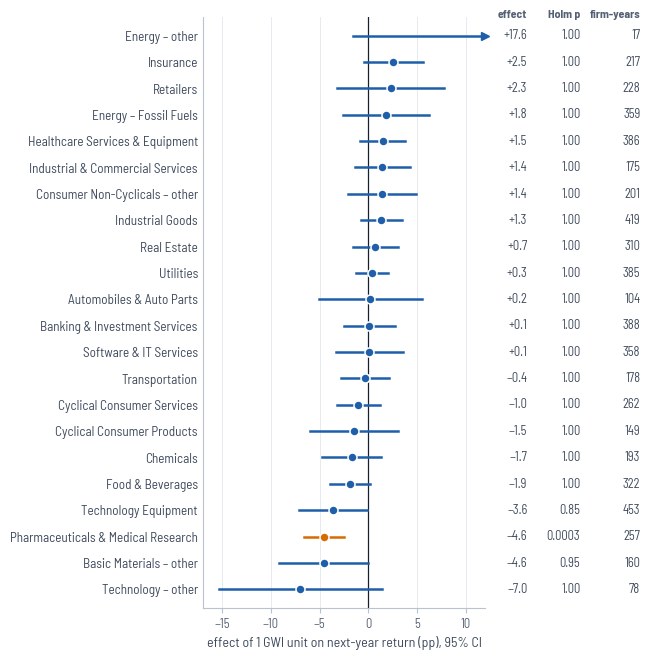

Off the scale: Energy - other, +17.6 per GWI unit, 17 firm-years


In [22]:
# Figure 6 of the memo: the 22 business-sector groups
s22p = s22.sort_values('effect', ascending=False)
labels22 = [g.replace(' - ', ' – ') for g in s22p.group]
colors = [ORANGE if c == G else BLUE for c in s22p.index]
fig, ax = plt.subplots(figsize=(6.5, 6.6))
yy = np.arange(len(s22p))[::-1]
x0, x1 = -17, 12                                       # axis cut: the 17-firm-year "Energy - other" group lies off the scale
for yi, (_, r), c in zip(yy, s22p.iterrows(), colors):
    l, h = r.effect - 1.96 * r.se, r.effect + 1.96 * r.se
    ax.plot([max(l, x0), min(h, x1)], [yi, yi], color=c, lw=1.8)
    if h > x1:
        ax.plot([x1], [yi], marker='>', ms=6, color=c, clip_on=False)
    if l < x0:
        ax.plot([x0], [yi], marker='<', ms=6, color=c, clip_on=False)
    if x0 <= r.effect <= x1:
        ax.scatter([r.effect], [yi], s=42, color=c, zorder=3, **RING)
ax.set_xlim(x0, x1)
ax.axvline(0, color=INK, lw=0.9, zorder=1)
ax.set_yticks(yy, labels22)
ax.tick_params(axis='y', length=0, labelcolor=INK2, labelsize=9.5)
ax.grid(axis='y', visible=False)
ax.set_ylim(-0.7, len(s22p) - 0.3)
ax.set_xlabel('effect of 1 GWI unit on next-year return (pp), 95% CI')
table_cols = [('effect', [fmt(v, 1) for v in s22p.effect], 0.42),
              ('Holm p', [f'{p:.4f}' if p < .01 else f'{p:.2f}' for p in s22p.p_holm], 0.95),
              ('firm-years', [f'{n:,}' for n in s22p.n], 1.55)]
for head, vals, dx in table_cols:                     # number columns right of the axes, dx inches from its edge
    tr = matplotlib.transforms.offset_copy(ax.get_yaxis_transform(), fig=fig, x=dx * 72, units='points')
    for yi, t in zip(yy, vals):
        ax.text(1, yi, t, transform=tr, va='center', ha='right', fontsize=9, color=INK2)
    ax.text(1, len(s22p) - 0.4, head, transform=tr, va='bottom', ha='right', fontsize=8.5, color=MUTED, fontweight=600)
fig._fit_right = True
save_figure(fig, 'figure6_sectors_22.png')
off = s22p.iloc[0]
print(f'Off the scale: {off.group}, {fmt(off.effect, 1)} per GWI unit, {off.n} firm-years')

**What we find.** No sector effect is reliable. Across the 10 economic sectors, Basic Materials shows the largest penalty (−2.59 per GWI unit, p = 0.028 on its own), but p is 0.28 after correcting for ten tests, and the shuffle test produces a sector at least this strong 18% of the time. Across the 22 groups (Figure 6), pharmaceuticals shows a large effect (−4.6 per GWI unit; 29 firms, 257 firm-years) that meets the pre-set rule: Holm p = 0.0003, the same sign in both halves, and no sign flip when any one firm is dropped. It stays a lead rather than a finding for three reasons. The shuffle test produces a group this strong 12% of the time; eleven generics, distribution and contract-research firms account for about 80% of the slope; and allowing for business models (generic drug makers and lab-tool firms that talked green and did poorly, set against distributors that said little and did well) shrinks it to about −3, with p between 0.05 and 0.25. For an allocator this points to a handful of firms, not a sector-wide penalty.

## 11. Every number in the memo, traced
Each row is a number (or set of numbers) printed in the memo, the section where it appears, and the value computed in this notebook, formatted the way the memo rounds it. `match` compares the two after removing signs, commas, spaces and percent signs; the few numbers the memo states approximately ("about 5", "about 80%", "about −3") are compared with a stated tolerance. The last line stops the run if anything differs.

Numbers in Part III (literature review) come from the cited papers, and the data-pull dates from `data/PULL_DATES.csv` (section 2.1); they are not computed here.

\* In the last column of Table 2, two cells of the memo draft (+0.69 and +3.12) had been computed with the top-versus-bottom multiplier rounded to 2.82; with the exact multiplier (2.8222, section 5) they are +0.70 and +3.13, the values used in the final memo and checked here.

In [23]:
L = lambda v, d=2: f'{v:.{d}f}'
ex3_holm = explo.loc['GWI on the two-year return t+1..t+2', 'Holm p (3 tests)']
bmat = s10.loc['51']
off = s22.loc[s22.effect.idxmax()]
t1 = lambda k: f"{L(h1.params[k])} | {L(h1.bse[k])} | {L(h1.tvalues[k])} | {L(h1.pvalues[k], 3)} | {L(ci1.loc[k, 0])} to {L(ci1.loc[k, 1])}"
t2 = lambda r: ' | '.join(table2.loc[r])
t3 = lambda r: ' | '.join(table3.loc[r])
CHECKS = [
    # (memo location, what, memo text, notebook value)
    ('I; 5.2; Table 2', 'change after Paris (p)', '+0.50 (0.47)', f"{fmt(h2.params['gwi:post'])} ({L(h2.pvalues['gwi:post'])})"),
    ('I; 5.3; 6.1', 'filing reaction per GWI unit (p); top vs bottom fifth', '-0.087 (0.051); -0.25', f"{L(e1.params['gwi'], 3)} ({L(e1.pvalues['gwi'], 3)}); {L(e1.params['gwi'] * q5)}"),
    ('I; 5.5; 6.1', 'rating gap of emission reporters (t); after size', '37 (26); 31', f"{gap_rep.params['reports']:.0f} ({gap_rep.tvalues['reports']:.0f}); {gap_rep2.params['reports']:.0f}"),
    ('I; 5.5', 'rating change per 50 ranks of Walk (t)', '-2.0 (-1.2)', f"{L(50 * on.params['walk'], 1)} ({L(on.tvalues['walk'], 1)})"),
    ('I; 5.5; Table 4', 'top-fifth overlap with rating-based GWI', '43%', f'{overlap:.0%}'),
    ('I; 4.5; 5.1; 6.2', 'largest penalty not ruled out, pp a year', '2.8', L(abs(lo * q5), 1)),
    ('Fig. 1; 4.4; Fig. 3; Table 4', 'GWI firm-years', '5,635', f'{len(gs):,}'),
    ('4.1', 'S&P 500 firm-years', '7,529', f'{len(panel):,}'),
    ('4.1', 'removed: total, duplicates, wrong-company 10-Ks', '53, 47, 6', f"{int(panel.excluded.sum())}, {excl['duplicate listing']}, {excl['wrong-company 10-K']}"),
    ('4.1', 'firm-years after the identity corrections', '7,476', f'{len(P):,}'),
    ('4.1; Table 1; Fig. 4', 'regression sample: firm-years, firms, companies', '5,600, 673, 651', f'{len(base):,}, {base.firm_id.nunique()}, {base.entity.nunique()}'),
    ('4.1; 6.2', 'share reporting emissions 2010, 2024; not reporting 2010, 2024', '60%, 94%; 40%, 6%', f'{reporting.loc[2010]:.0%}, {reporting.loc[2024]:.0%}; {1 - reporting.loc[2010]:.0%}, {1 - reporting.loc[2024]:.0%}'),
    ('4.1; 6.2', 'median market value without vs with emissions (US$ bn)', '12.9 vs 24.6', f'{mv_no:.1f} vs {mv_yes:.1f}'),
    ('Fig. 2', 'dropped: no emissions data, no Talk, < 5 peers', '1,806, 32, 3', ', '.join(f'{v:,}' for v in drop.values())),
    ('4.1', 'Yahoo returns: total, no LSEG return, LSEG price-only', '57, 12, 45', f"{src.get('yahoo', 0) + src.get('yahoo_divfix', 0)}, {src.get('yahoo', 0)}, {src.get('yahoo_divfix', 0)}"),
    ('4.1', 'audit: re-linked, revenue as filed, emission values set to missing', '171, 181, 47', ', '.join(str(int(v)) for v in audit['count'].iloc[[0, 1, 4]])),
    ('4.1', 'Agilent fiscal 2013 revenue, LSEG vs 10-K (US$ bn)', '3.9 vs 6.8', f"{audit['count'].iloc[2]} vs {audit['count'].iloc[3]}"),
    ('4.1', 'LSEG revenue as delivered (p) vs main estimate', '-0.28 (0.42) vs -0.32', f"{L(more.loc['LSEG revenue as delivered', 'effect'])} ({L(more.loc['LSEG revenue as delivered', 'p'])}) vs {L(b1)}"),
    ('4.2; 6.2', 'Talk measures: correlation raw, ranked', '0.87, 0.69', f'{L(r_talk_raw)}, {L(r_talk_rank)}'),
    ('4.4; Table 1', 'rank points per GWI unit', '45.2', L(GWI_UNIT, 1)),
    ('Fig. 3', 'GWI fifths: top, bottom', '+1.40, -1.42', f'{fmt(gs.gwi[top].mean())}, {fmt(gs.gwi[bot].mean())}'),
    ('4.6; 5.4', 'robustness variants in Table 3; shuffles', '11; 1,000', f'{len(rob) - 1}; {N_SHUFFLE:,}'),
    ('5.1', 'top vs bottom fifth (p); range', '-0.9 (0.35); -2.8 to +1.0', f"{L(b1 * q5, 1)} ({L(h1.pvalues['gwi'])}); {L(lo * q5, 1)} to {fmt(hi * q5, 1)}"),
    ('5.1', 'p of profitability and leverage', '0.020 and 0.025', f"{L(h1.pvalues['roa_w'], 3)} and {L(h1.pvalues['lev_w'], 3)}"),
    ('5.1; Table 1', 'R-squared: model, fixed effects only (%)', '21.4, 21.1', f'{h1.rsquared * 100:.1f}, {r2_fe * 100:.1f}'),
    ('5.1', 'Talk and Walk entered separately (p)', '-0.27 (0.45); +0.15 (0.69)', f"{L(sep.params['talk_z'])} ({L(sep.pvalues['talk_z'])}); {fmt(sep.params['walk_z'])} ({L(sep.pvalues['walk_z'])})"),
    ('5.1; 6.1', 'two-year window: top vs bottom gap, p, Holm p (3 tests)', '3.4, 0.11, 0.32', f"{abs(ex3.params['gwi'] * q5):.1f}, {L(ex3.pvalues['gwi'])}, {L(ex3_holm)}"),
    ('Table 1', 'GWI row', '-0.32 | 0.34 | -0.93 | 0.354 | -0.99 to 0.35', t1('gwi')),
    ('Table 1', 'size row', '0.52 | 0.38 | 1.37 | 0.171 | -0.22 to 1.26', t1('size_mv_w')),
    ('Table 1', 'ROA row', '16.19 | 6.95 | 2.33 | 0.020 | 2.57 to 29.80', t1('roa_w')),
    ('Table 1', 'leverage row', '4.65 | 2.07 | 2.25 | 0.025 | 0.59 to 8.71', t1('lev_w')),
    ('Table 1', 'top vs bottom fifth row (x 2.82)', '2.82: -0.89 | 0.354 | -2.79 to 1.00', f"{L(q5)}: {L(b1 * q5)} | {L(h1.pvalues['gwi'], 3)} | {L(lo * q5)} to {L(hi * q5)}"),
    ('Table 1', 'note: clusters, R-squared, R-squared FE, ROA +10 pp', '651, 0.214, 0.211, 1.6', f"{h1.n_clusters}, {L(h1.rsquared, 3)}, {L(r2_fe, 3)}, {L(0.1 * h1.params['roa_w'], 1)}"),
    ('Fig. 4', 'groups of firm-years; Table 1 slope (p)', '20 of 280; -0.32 (0.35)', f"{len(bn)} of {bn.n.iloc[0]}; {L(b1)} ({L(h1.pvalues['gwi'])})"),
    ('5.2', 'gap before / after Paris, pp a year', '1.9 / 0.4', f"{abs(h2.params['gwi'] * q5):.1f} / {abs(after_b * q5):.1f}"),
    ('5.2', 'p without 2010; p with 2015 as post-Paris', '0.73; 0.15', f"{L(h2_no2010.pvalues['gwi:post'])}; {L(h2_2015.pvalues['gwi:post15'])}"),
    ('5.2', 'Wald tests: pre-Paris equal, all 15 equal, all 15 zero', '0.36, 0.52, 0.50', f'{L(p_pre_equal)}, {L(p_all_equal)}, {L(p_all_zero)}'),
    ('Table 2', 'before Paris', '-0.66 | 0.55 | 0.232 | -1.86', t2('Annual return: before Paris (10-Ks 2010-15)')),
    ('Table 2', 'change after Paris', '+0.50 | 0.69 | 0.466 | +1.42', t2('Annual return: change after Paris')),
    ('Table 2', 'after Paris', '-0.16 | 0.43 | 0.716 | -0.44', t2('Annual return: after Paris (10-Ks 2016-24)')),
    ('Table 2 *', 'change excluding 2010', '+0.25 | 0.71 | 0.730 | +0.70', t2('Change after Paris, excluding 2010')),
    ('Table 2 *', 'change with 2015 as post-Paris', '+1.11 | 0.78 | 0.153 | +3.13', t2('Change after Paris, 2015 10-Ks counted as post-Paris')),
    ('Table 2', '3-day filing reaction', '-0.087 | 0.044 | 0.051 | -0.25', t2('3-day filing reaction (vs S&P 500)')),
    ('Table 2; 5.3', '3-day reaction, change after Paris', '+0.055 | 0.085 | 0.522 | +0.15', t2('3-day filing reaction: change after Paris')),
    ('Table 2; 5.3; 6.1', 'N annual, without 2010, filings; Holm p', '5,600, 5,311, 5,610; 0.101', f'{int(h2.nobs):,}, {int(h2_no2010.nobs):,}, {int(e1.nobs):,}; {L(holm2[1], 3)}'),
    ('5.4', 'smallest p; range without April; with bm and momentum', '0.18; -0.08 to -0.46; -0.38', f"{L(rob.p.iloc[1:].min())}; {L(others.effect.max())} to {L(others.effect.min())}; {L(rob.loc['Adding book-to-market and past-year return', 'effect'])}"),
    ('5.4; 6.2', 'April window (p)', '+0.18 (0.63)', f"{fmt(rob.loc['Return from April, after the 10-K is public', 'effect'])} ({L(rob.loc['Return from April, after the 10-K is public', 'p'])})"),
    ('5.4', 'further checks: smallest p', '0.17', L(more.p.min())),
] + [('Table 3', r, memo, t3(r)) for r, memo in [
    ('Main model (Table 1)', '-0.32 | 0.35 | 5,600'), ('No size, ROA or leverage controls', '-0.42 | 0.23 | 5,600'),
    ('Adding book-to-market and past-year return', '-0.38 | 0.27 | 5,359'),
    ('Walk adds LSEG estimates for non-reporters', '-0.29 | 0.39 | 5,934'),
    ('Walk = LSEG Environmental Pillar rank', '-0.08 | 0.79 | 6,999'), ('Peers = Fama-French 12 industries', '-0.33 | 0.39 | 5,588'),
    ('Talk from FinBERT only', '-0.46 | 0.18 | 5,600'), ('Talk from Loughran-McDonald only', '-0.22 | 0.52 | 5,600'),
    ('Return from April, after the 10-K is public', '+0.18 | 0.63 | 5,562'), ('Excluding financial firms', '-0.40 | 0.27 | 4,994'),
    ('Sector-by-year fixed effects', '-0.31 | 0.35 | 5,600'),
    ('Fama-MacBeth (one regression per year, averaged)', '-0.35 | 0.32 | 5,600')]] + [
    ('5.5; Table 4', 'correlations: rating-Walk, rating-Talk, Talk-Walk', '-0.07, +0.16, -0.17', f'{fmt(rho_rating_walk)}, {fmt(rho_rating_talk)}, {fmt(rho_tw)}'),
    ('Table 4', 'reporting gap (t); after size', '+37.3 (26.0); +31.3', f"{fmt(gap_rep.params['reports'], 1)} ({L(gap_rep.tvalues['reports'], 1)}); {fmt(gap_rep2.params['reports'], 1)}"),
    ('5.5; Table 4', 'Talk +50 ranks (t); Walk +50 ranks (t)', '+7.9 (5.1); -2.0 (-1.2)', f"{fmt(50 * on.params['talk_epm'], 1)} ({L(on.tvalues['talk_epm'], 1)}); {fmt(50 * on.params['walk'], 1)} ({L(on.tvalues['walk'], 1)})"),
    ('Table 4', 'N: GWI sample, reporter gap', '5,635, 7,059', f'{len(gs):,}, {int(gap_rep.nobs):,}'),
    ('5.6', 'Basic Materials: effect (p), Holm p, shuffle', '-2.59 (0.028), 0.28, 18%', f'{L(bmat.effect)} ({L(bmat.p, 3)}), {L(bmat.p_holm)}, {p10_shuffle:.0%}'),
    ('5.6; Fig. 6', 'pharma: effect, firms, firm-years, Holm p, shuffle', '-4.6, 29, 257, 0.0003, 12%', f"{L(ph.effect, 1)}, {base.loc[base.bs.eq(G), 'firm_id'].nunique()}, {int(ph.n)}, {L(ph.p_holm, 4)}, {p22_shuffle:.0%}"),
    ('5.6', 'pharma halves same sign; sign flips leaving one firm out', 'yes; 0', f"{'yes' if mh.params['s_G_early'] * mh.params['s_G_late'] > 0 else 'no'}; {int((lofo >= 0).sum())}"),
    ('5.6', 'pharma: business-model p range', '0.05-0.25', f'{L(bmv.p.min())}-{L(bmv.p.max())}'),
    ('Fig. 6', 'groups; pooling threshold; off-scale group effect, firm-years', '22; 100; +17.6, 17', f'{len(s22)}; {POOL}; {fmt(off.effect, 1)}, {int(off.n)}'),
]
APPROX = [   # numbers the memo states approximately: (location, what, memo text, value, target, tolerance)
    ('4.5; 6.2', 'detectable change after Paris, pp a year', 'about 5', h2_mde * q5, 5, 0.6),
    ('5.6', 'share of the pharma slope from the eleven firms', 'about 80%', share * 100, 80, 2),
    ('5.6', 'pharma effect allowing for business models (mean of the three versions)', 'about -3', bmv.effect.mean(), -3, 0.5),
]
norm = lambda s: s.replace('−', '-').replace('+', '').replace(',', '').replace(' ', '').replace('%', '')
chk = pd.DataFrame(CHECKS, columns=['memo', 'number', 'memo says', 'notebook'])
chk['match'] = np.where(chk['memo says'].map(norm) == chk['notebook'].map(norm), 'yes', 'NO')
app = pd.DataFrame([(w, n, m, f'{v:.1f}', 'yes' if abs(v - t) <= tol else 'NO') for w, n, m, v, t, tol in APPROX],
                   columns=['memo', 'number', 'memo says', 'notebook', 'match'])
chk = pd.concat([chk, app], ignore_index=True)
with pd.option_context('display.max_rows', 200, 'display.max_colwidth', 70):
    display(chk)
n_ok = (chk.match == 'yes').sum()
print(f'{n_ok} of {len(chk)} memo entries match the notebook.')
assert n_ok == len(chk), chk[chk.match != 'yes']

,memo,number,memo says,notebook,match
0,I; 5.2; Table 2,change after Paris (p),+0.50 (0.47),+0.50 (0.47),yes
1,I; 5.3; 6.1,filing reaction per GWI unit (p); top vs bottom fifth,-0.087 (0.051); -0.25,-0.087 (0.051); -0.25,yes
2,I; 5.5; 6.1,rating gap of emission reporters (t); after size,37 (26); 31,37 (26); 31,yes
3,I; 5.5,rating change per 50 ranks of Walk (t),-2.0 (-1.2),-2.0 (-1.2),yes
4,I; 5.5; Table 4,top-fifth overlap with rating-based GWI,43%,43%,yes
5,I; 4.5; 5.1; 6.2,"largest penalty not ruled out, pp a year",2.8,2.8,yes
6,Fig. 1; 4.4; Fig. 3; Table 4,GWI firm-years,"5,635","5,635",yes
7,4.1,S&P 500 firm-years,"7,529","7,529",yes
8,4.1,"removed: total, duplicates, wrong-company 10-Ks","53, 47, 6","53, 47, 6",yes
9,4.1,firm-years after the identity corrections,"7,476","7,476",yes


72 of 72 memo entries match the notebook.


## 12. Session information

In [24]:
written = sorted(os.listdir(FIGS))
print('Figures written to figures/:', ', '.join(written))
print(f'Python {sys.version.split()[0]} on {sys.platform} | numpy {np.__version__} | pandas {pd.__version__} | '
      f'scipy {scipy.__version__} | statsmodels {statsmodels.__version__} | matplotlib {matplotlib.__version__}')
print(f'Random seed {SEED}; run time {time.time() - T0:.0f} s; finished {time.strftime("%Y-%m-%d %H:%M")}')

Figures written to figures/: figure1_talk_vs_walk.png, figure2_sample_flow.png, figure3_gwi_distribution.png, figure4_h1_binned_scatter.png, figure5_h2_yearly_effects.png, figure6_sectors_22.png
Python 3.12.10 on win32 | numpy 2.4.1 | pandas 2.3.3 | scipy 1.17.0 | statsmodels 0.14.6 | matplotlib 3.10.8
Random seed 5324; run time 8 s; finished 2026-10-27 12:50
